> **Recommended: run this notebook in Google Colab, nothing to install.**
>
> [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/04-how-navigate-solves.ipynb)
>
> Just click on the "Open in Colab" button and follow along. Click the ▶ button on each cell (or press Shift+Enter) to see the results and move on to the next one.
>
> If you can't or don't want to use Colab, the documentation website shows the pre-run results.

# Session 4: How Navigate solves

[Session 3](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/03-how-a-navigate-model-is-built.ipynb) showed how the case of [Session 1](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/01-run-a-simple-case.ipynb) is built and the data behind it. This session follows Navigate as it solves that case: how it decides, step by step, for the shipowners, operators and fuel producers, the results it produces, and how much the owners' behaviour matters.

![Map of the Chile to Rotterdam copper trade: the two bunker ports, a fleet of ships on the voyage via the Panama Canal, and the fuel production sites in Patagonia and southern Sweden, both of which make e-methanol and e-ammonia, with bio-methanol in Sweden as well](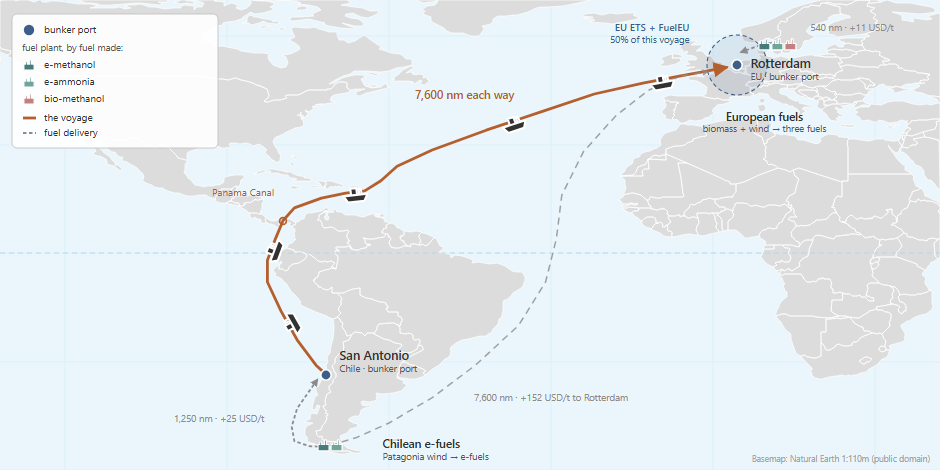)

*San Antonio to Rotterdam via the Panama Canal: the two bunker ports, the
voyage, and the possible fuel plants.*

## What you'll do

**Part 1: Understand the logic behind the model.** Understand how Navigate decides, for the shipowners and operators and for the fuel producers, and see the results it produces.

**Part 2: How much behaviour matters.** Change how sharply the fleet and plant owners decide and see what it does to the results.


## Setup

Run the cell below on Colab or locally to set up the Navigate model. It also loads the pre-made example that will be used to illustrate this part of the workshop.

In [ ]:
# @title Setup
# Setup. Works both on Google Colab and in a local checkout of the repository.
import os
from pathlib import Path


# The branch these notebooks live on, and the one Colab clones. The "Open in
# Colab" badge at the top of the notebook, like the links between the
# notebooks, opens the copy on the workshop-colab branch instead: the same
# notebooks with their outputs cleared, rebuilt from this branch by
# .github/workflows/workshop-colab.yml. Change BRANCH, and that workflow, to
# "main" once the branch has been merged.
BRANCH = "dev-workshop"


def at_repo_root() -> bool:
    """True if the working directory is the root of the repository."""
    return Path("navigate").is_dir() and Path("assumptions").is_dir()


if at_repo_root():
    print("Already at the repository root.")
elif Path("../../navigate").is_dir():
    # Local Jupyter starts the kernel in the notebook's own folder,
    # docs/workshop/, but the paths below are relative to the repository root.
    os.chdir("../..")
    print("Moved up to the repository root.")
else:
    # Colab, or any other fresh environment
    if not Path("navigate-zcs").is_dir():
        !git clone --depth 1 -b {BRANCH} https://github.com/zerocarbonshipping/navigate-zcs.git
    os.chdir("navigate-zcs")
    print("Cloned the repository and moved into it.")

assert at_repo_root(), f"not at the repository root: {Path.cwd()}"

# `import navigate` is not a usable test here: from the repository root it
# succeeds because the source folder is present, which leaves the `navigate`
# command itself missing.
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    print(f"Navigate {version('navigate-zcs')} is already installed.")
except PackageNotFoundError:
    %pip install -q .
    print("Installed Navigate.")


# Load the example deck.
EXAMPLE = Path("simulations/examples/example_4")

# Fail loudly rather than printing an empty list. The setup above clones the
# branch named in BRANCH, so this deck is only here once it has been committed
# and pushed to that branch.
assert EXAMPLE.is_dir(), (
    f"{EXAMPLE} not found under {Path.cwd()}. On Colab the setup cell clones the "
    f"{BRANCH!r} branch, so this deck has to be committed and pushed there "
    "before the notebook can read it."
)


def show(path, first=None, grep=None, code_only=False):
    """Print a deck file: all of it, the first N lines, matching lines, or the
    command lines only (`code_only`, which drops the comments)."""
    lines = Path(path).read_text(encoding="utf-8").splitlines()
    if code_only:
        print(f"# {Path(path).name}: command lines only, "
              f"open the file for the commentary")
        lines = [ln for ln in lines if ln.strip() and not ln.strip().startswith("#")]
    if grep:
        lines = [ln for ln in lines if grep in ln]
    if first:
        lines = lines[:first]
    for ln in lines:
        print(ln)


deck = sorted(EXAMPLE.rglob("*.nav")) + sorted(EXAMPLE.rglob("*.inc"))
assert deck, f"no .nav or .inc files under {EXAMPLE.resolve()}"


# What this session needs from Session 3's cells, copied from them: the imports,
# the deck's path, the solver guard, the house style, the share curves of the
# decision sensitivities and one label style. Nothing is parsed or solved here;
# the run this session walks through is solved further down.
import argparse
import contextlib
import io

import numpy as np
import pandas as pd
from navigate.bunker.bunker_algorithm import BunkerAlgorithm
from navigate.core.enum_ import BunkerScopeID
from navigate.core.expectations.vessel_expectation import VesselExpectation
from navigate.fuel.producer import producer_planning
from navigate.vessel.fleet import fleet_technology
from navigate.manager import SimulationManager

# This version of Navigate's solver can hang on one year of a run. This caps the
# method that hangs and solves that year again with another one; runs that solve
# today are unchanged. See _solver.py.
_STYLE_DIR = str(Path("docs/workshop").resolve())
if _STYLE_DIR not in sys.path:
    sys.path.insert(0, _STYLE_DIR)
from _solver import guard_interior_point

guard_interior_point()

NAV = Path("simulations/examples/example_4/example_4.nav")
ARGS = argparse.Namespace(data_dir=Path("./assumptions"), solver=None)

import matplotlib.pyplot as plt


# One house style for every figure in the workshop. It lives in
# docs/workshop/_style.py rather than in this cell, so that this notebook and
# notebook 2 cannot drift apart - which is exactly what had happened. The
# colours are Navigate's own, and that file explains the one thing about them
# that surprises people: the hue says how a fuel was MADE, not which molecule it
# is, so bio-methanol and e-methanol are deliberately different colours.
from _style import (AXIS, BLUE, GREEN, GRID, INK, MUTED, ORANGE, PALE, SUBINK,
                    TICK, config_colour, config_label, cost_colour, fuel_colour,
                    fuel_label, fuel_sorted, series_colours)


# The share curves of the decision sensitivities, as Session 3 draws them.
def share_by_cost(gap, odds):
    """Share of a fuel type whose cost is `gap` above (or below) the other's."""
    beta = -np.log(odds) / np.log(1.1)
    return 1 / (1 + (1 + gap) ** beta)


def share_by_npv(npv_over_capex, odds):
    """Share of eligible ships that convert, against keeping the ship."""
    beta = np.log(odds) / 0.05
    return 1 / (1 + np.exp(-beta * npv_over_capex))


def style(ax, title, xlab):
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    ax.set_xlabel(xlab, fontsize=8, color=SUBINK)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:+.0%}" if x else "0")
    ax.axhline(0.5, color=AXIS, lw=0.8, zorder=1)
    ax.axvline(0, color=AXIS, lw=0.8, zorder=1)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)


# The white box behind numbers printed on bars.
LABEL_BOX = dict(boxstyle="square,pad=0.15", fc="white", ec="none")


---

## Part 1: Understand the logic behind the model

The idea of Navigate is to mimic the decision behaviour of shipowners, operators and fuel producers to understand how the fleet transition may evolve under a given set of conditions.

The aim of this section is to go "inside Navigate's mind" and understand how the model solving actually works, step by step.

### How Navigate decides

Navigate gives a solution one year at a time.
The solving process is the same for each year and each decision maker in the model:

1. **look ahead**: make projections about the future
2. **decide**: make some calculations based on your projections and take some decisions that make sense from an economic perspective. Decisions are also influenced by the behaviour traits of the decision maker: inertia and sensitivity
3. **commit**: decisions have been taken and the other actors react; check how the fleet operates in "reality", which may differ from previously formed expectations.

In more detail, the model starts the year by calculating expectations and beliefs about the future from the information available — among them a look-ahead bunkering optimisation, which prices the year before anything is decided. Those expectations then inform the decisions of the owners and the operators, in this order:

- efficiency measures (owners): implement (or not) efficiency technology, on existing ships when they reach their five-yearly retrofit cycle and on any ship ordered new
- operational measures (operators): change the vessels' sailing speed (while minimizing total cost per cargo-mile)
- fleet management (owners): scrap (automatic based on lifetime), retrofit or order new ships
- fuel bunkering (operators): which fuel to buy at which port for this year

The bunkering optimisation therefore runs twice: once as a forecast that informs the four
decisions, and once at the end of the year to commit.

What drives the decisions of the owners is mostly economic considerations, supplemented by some behavioural traits. When choosing the fuel type of new ships, owners lean towards the cheapest option but are not blind to the others: `InterFuelSensitivity` sets how sharply a cost gap between fuel types (e.g. ammonia or LNG) turns into a change of mind, and `IntraFuelSensitivity` does the same between ship designs that burn the same fuel type (this deck has only one design per fuel type, so that second axis does not decide anything here).

In other words, in Navigate, there is no "absolute winner": each option gets a **share**, larger when it is cheaper, and the sensitivities (~behavioral traits) in the deck set how sharply a cost gap turns into a share. With 300 ships those shares read as ships — "12 % e-ammonia" is about thirty-six hulls.

The fuel producers decide last, in the same year, basing their decisions on the expected fuel demand from the shipping sector: if that demand exceeds the supply already built or ordered, each producer takes its share of the expected unmet demand and turns that into fuel plants. Here too there is no "absolute winner", only shares.

Now, run the next cell that solves the model and "extracts" some information along the solving process that we can observe and analyse.


In [ ]:
# @title Run the case and record what the actors believe
def run_case(tweak=None, probe_fn=None, quiet=True):
    """Parse the deck, optionally modify it, solve it, return the manager.

    With `probe_fn`, `SimulationManager._perform_time_step` is wrapped for the
    duration of the run and `probe_fn(m, idx)` is called at the end of every
    time step, so the actors' beliefs can be copied out before the next step
    overwrites them. The patch is on the class and is always put back.

    Returns `(manager, snapshots)` when probing, the manager alone otherwise.
    """
    m = SimulationManager()
    snaps = {}
    original = SimulationManager._perform_time_step

    # The expected fuel mix cannot be read after the fact: BunkerAlgorithm.transfer()
    # resets the accumulator on EVERY forward solve, so by the end of a step it holds
    # one year. Wrapping transfer is the only way to add the forward years up while
    # they exist. Only the EXPECTED scope is collected - the binding solve is Stage 4's.
    original_transfer = BunkerAlgorithm.transfer
    expected_mix, expected_first, outer = {}, {}, {"idx": 0, "call": 0}
    # The same forward solves kept apart, one entry per forward year, with what it
    # takes to say WHY a hull expects what it does: the supply each port was
    # expected to offer, which of the hull's supply caps bound, and how much oil
    # its dual-fuel engines burn above their minimum pilot share.
    expected_by_year = {}

    # The technology NPV is computed inside perform_technology_installation and
    # thrown away once the shares are drawn, so the only way to see the number the
    # decision was actually made on is to record it as it is produced. One call per
    # vessel per step, in fleet.assets order.
    # The NPV function is defined in navigate/vessel/package.py;
    # fleet_technology imports it and calls it unqualified, so the name
    # it calls is the one that has to be patched.
    original_npv = fleet_technology.npv_for_newbuilds
    npv_log = {}

    def wrapped_npv(packages_saving, packages, discount_rate):
        out = original_npv(packages_saving, packages, discount_rate)
        npv_log.setdefault(outer["idx"], []).append(np.asarray(out, dtype=float).copy())
        return out

    # The delivered-cost split is computed and thrown away: calculate_modelled_uptake
    # returns a share per plant and only the resulting plant COUNT is kept, so which
    # site the producer chose cannot be read back afterwards.
    original_uptake = producer_planning.calculate_modelled_uptake
    uptake_log = {}

    def wrapped_uptake(producer):
        out = original_uptake(producer)
        uptake_log.setdefault(outer["idx"], []).append(
            (producer.get_name(), [a.get_name() for a in producer.assets],
             np.asarray(out, dtype=float).copy()))
        return out

    # The gap a producer plans on is demand minus the supply of its running and
    # ordered plants. Both are overwritten once it has planned, so they are copied
    # here, just before: its supply, and its share of the gap, per fuel, tons/yr.
    from navigate.fuel.producer.producer import Producer
    original_planning = Producer.perform_planning
    balance_log = {}

    def wrapped_planning(self, timeline, time_step, idx):
        fair = self.expectation.get_fair_share_demand()
        for fuel in self.get_fuels():
            supply = sum(np.asarray(self.expectation.get_guaranteed_production(
                             plant.get_name()), dtype=float)
                         for plant in self.assets if plant.fuel.get_name() == fuel)
            balance_log.setdefault(idx, {})[(self.get_name(), fuel)] = {
                "supply": np.array(supply, dtype=float),
                "gap": np.array(fair[fuel], dtype=float)}
        return original_planning(self, timeline, time_step, idx)

    # The belief keeps compliance as ONE untagged number: remedial, pooling and
    # surplus all land in the same `_policy_expenses` array, and it is wiped at
    # the top of every look-ahead. Booking each contribution as it is made, and
    # clearing the book on the same reset the model uses, is the only way to
    # split the expected bill the way Stage 4 splits the committed one.
    original_add = VesselExpectation.add_policy_expenses
    original_add_path = VesselExpectation.add_policy_expenses_path
    original_reset = VesselExpectation.reset_expected_bunkering
    policy_book = {}

    def _book(idx, value, caller):
        """Credit one contribution to the scheme and ship settling it.

        The regulation name is not passed to add_policy_expenses, so the only
        place it still exists is the caller's own locals. The frame is handed in
        rather than counted back to, so adding a wrapper cannot silently break it.
        """
        local = caller.f_locals
        name = local.get("r")
        if name is None and "regulation" in local:
            name = local["regulation"].get_name()
        vessel = local.get("v") or local.get("vessel_name")
        if name and vessel:
            key = (idx, vessel, name)
            policy_book[key] = policy_book.get(key, 0.) + float(value)

    def wrapped_add(self, idx, expenses):
        _book(idx, expenses, sys._getframe(1))
        return original_add(self, idx, expenses)

    def wrapped_add_path(self, idx, expenses):
        caller = sys._getframe(1)
        for offset, value in enumerate(np.atleast_1d(np.asarray(expenses, dtype=float))):
            _book(idx + offset, value, caller)
        return original_add_path(self, idx, expenses)

    def wrapped_reset(self):
        # every vessel is reset in one loop before the look-ahead runs, so
        # clearing the whole book on any one of them is correct and simpler
        policy_book.clear()
        return original_reset(self)

    def wrapped_transfer(alg):
        original_transfer(alg)
        if alg.scope is not BunkerScopeID.EXPECTED:
            return
        outer["call"] += 1
        store = expected_mix.setdefault(outer["idx"], {})
        # call 1 is this step's own year; the rest are the years beyond it
        first = expected_first.setdefault(outer["idx"], {}) if outer["call"] == 1 else None
        for vessel_name, vessel in alg.vessels.items():
            for port_name in alg.ports:
                for fuel_name in alg.fuels:
                    tons = vessel.expectation.get_bunker_mass_expected(port_name, fuel_name)
                    if tons > 0.:
                        key = (vessel_name, port_name, fuel_name)
                        store[key] = store.get(key, 0.) + tons
                        if first is not None:
                            first[key] = first.get(key, 0.) + tons
        year = {"mix": {}, "by_port": {}, "supply": {}, "capped": set(), "inertia": set(), "excess_oil": {},
                "usable": {v: list(alg.usable_fuels[v]) for v in alg.vessels}}
        for vessel_name, vessel in alg.vessels.items():
            for port_name in alg.ports:
                for fuel_name in alg.fuels:
                    tons = vessel.expectation.get_bunker_mass_expected(port_name, fuel_name)
                    if tons > 0.:
                        key = (vessel_name, fuel_name)
                        year["mix"][key] = year["mix"].get(key, 0.) + tons
                        year["by_port"][(vessel_name, port_name, fuel_name)] = tons
        for port_name, port in alg.ports.items():
            for fuel_name in alg.fuels:
                year["supply"][(port_name, fuel_name)] = float(
                    port.expectation.get_bunker_supply(fuel_name, alg.idx))
        for key, constraint in alg.fair_share_fuel.items():
            if abs(constraint.Pi) > 1e-6:
                year["capped"].add(key)
        # the bunkering inertia: at least 70 % of last year's purchase of each fuel
        for key, constraint in alg.fuel_inertia.items():
            if abs(constraint.Pi) > 1e-6:
                year["inertia"].add(key)
        # energy per (vessel, converter): pilot fuel, and all of it
        pilot, burnt = {}, {}
        for spend in (alg.spend_sea, alg.spend_port):
            for (v, c, f, *_where), var in spend.items():
                converter = alg.converters[v][c]
                if not converter.is_dual_fuel() or var.X <= 0.:
                    continue
                energy = var.X * alg.effective_lhv[(v, c, f)]
                burnt[(v, c)] = burnt.get((v, c), 0.) + energy
                if any(f == fuel.get_name() for t in converter.pilot_fuel_types
                       for fuel in alg.fuels_per_fuel_type[t]):
                    pilot[(v, c)] = pilot.get((v, c), 0.) + energy
        for (v, c), total in burnt.items():
            floor = alg.converters[v][c].minimum_pilot_fuel.get() * total
            above = max(pilot.get((v, c), 0.) - floor, 0.)
            ex = year["excess_oil"].setdefault(v, [0., 0.])
            ex[0] += above
            ex[1] += total
        year["excess_oil"] = {v: a / t for v, (a, t) in year["excess_oil"].items() if t > 0}
        expected_by_year.setdefault(outer["idx"], {})[int(alg.idx)] = year

    def wrapped(self):
        outer["idx"] = self._idx              # so transfer knows which step it is in
        outer["call"] = 0                     # and which forward year within it
        original(self)                        # let the model do its work
        snap = probe_fn(self, self._idx)
        snap["expected_mix"] = expected_mix.pop(self._idx, {})
        snap["expected_mix_first"] = expected_first.pop(self._idx, {})
        snap["expected_by_year"] = expected_by_year.pop(self._idx, {})
        snap["npv_newbuild"] = npv_log.pop(self._idx, [])
        snap["producer_uptake"] = uptake_log.pop(self._idx, [])
        snap["producer_balance"] = balance_log.pop(self._idx, {})
        # the book is cleared by the next look-ahead, so copy it out now, exactly
        # as the beliefs above are copied out - the whole forward path, not just
        # this year: Stage 4's panel reads year one out of it and Stage 1's
        # per-year panels read all of it
        snap["expected_policy"] = {
            (v, r): np.array([policy_book.get((k, v, r), 0.)
                              for k in range(self._idx, self._timeline.size)])
            for v in self.nodes.vessels for r in self.nodes.regulations}
        snaps[self._idx] = snap

    if probe_fn is not None:
        SimulationManager._perform_time_step = wrapped
        BunkerAlgorithm.transfer = wrapped_transfer
        fleet_technology.npv_for_newbuilds = wrapped_npv
        producer_planning.calculate_modelled_uptake = wrapped_uptake
        Producer.perform_planning = wrapped_planning
        VesselExpectation.add_policy_expenses = wrapped_add
        VesselExpectation.add_policy_expenses_path = wrapped_add_path
        VesselExpectation.reset_expected_bunkering = wrapped_reset
    ctx = contextlib.redirect_stdout(io.StringIO()) if quiet else contextlib.nullcontext()
    try:
        with ctx:
            m.read_deck(NAV, ARGS)
            if tweak is not None:
                tweak(m)
            m.run()
    finally:
        if probe_fn is not None:              # only undo what we did
            SimulationManager._perform_time_step = original
            BunkerAlgorithm.transfer = original_transfer
            fleet_technology.npv_for_newbuilds = original_npv
            producer_planning.calculate_modelled_uptake = original_uptake
            Producer.perform_planning = original_planning
            VesselExpectation.add_policy_expenses = original_add
            VesselExpectation.add_policy_expenses_path = original_add_path
            VesselExpectation.reset_expected_bunkering = original_reset

    return (m, snaps) if probe_fn is not None else m


def years_of(m):
    return m.get_dateline().astype("datetime64[Y]").astype(int) + 1970


def fuel_frame(m):
    """Energy consumed per fuel per year, GJ."""
    fleet = m.nodes.fleets["copper_trade"]
    consumed = fleet.profile.get_consumed_energy()
    df = pd.DataFrame({k: v for k, v in consumed.items() if np.nansum(v) > 0},
                      index=years_of(m))
    return df.loc[:, df.sum().sort_values(ascending=False).index]


def probe(m, idx):
    """Everything the actors are 'thinking' at the end of time step idx.

    `expectation` is overwritten every time step, so a belief has to be copied
    out while it is still the one that step's decisions were taken on. `profile`
    persists and is read back later with an `idx`.
    """
    forward = np.s_[idx:]
    snap = {"operator": {}, "producer": {}, "regulation": {},
            "cohorts": [], "bunkered": {}, "fuel_demand": {}}

    # the operators: their forward view of what each configuration would cost
    for name, vessel in m.nodes.vessels.items():
        e = vessel.expectation
        snap["operator"][name] = {
            "expense_path": np.array(e.get_total_fuel_expenses(forward), dtype=float),
            # the same path split in two. get_total_fuel_expenses() returns their sum,
            # and only the private arrays keep them apart.
            "fuel_path": np.array(e._fuel_expenses[forward], dtype=float),
            "policy_path": np.array(e._policy_expenses[forward], dtype=float),
        }
        # this year's bunkering plan, tons per ship, per port and fuel. Reset at
        # the start of each existing-scope transfer, so it is unambiguously this
        # step's plan rather than a running total.
        for port in m.nodes.ports:
            for fuel in m.nodes.fuels:
                tons = float(e.get_bunker_mass_existing(port, fuel))
                if tons > 0:
                    snap["bunkered"][(name, port, fuel)] = tons

    # the fleet as cohorts. The profile keeps no history of increments, so the
    # only way to see a past year's age structure is to copy it out here.
    fleet = m.nodes.fleets["copper_trade"]
    for vessel, increments in zip(fleet.get_vessels(), fleet.get_multiplier_increments()):
        for inc in increments:
            snap["cohorts"].append((vessel.get_name(), inc.age, inc.multiplier))

    # the plants as cohorts, as the fleet above: running ones by age, and those
    # still under construction (the pipeline) at a negative age, the years until
    # they open. Each cohort's output is one plant's output in the year it was
    # sanctioned, as calculate_evolution_expectation reads it, in TJ/yr.
    from navigate.util import get_increments_origin_index
    from navigate.core.misc import YEAR
    years = m.get_timeline() / YEAR
    snap["plant_cohorts"] = []
    for producer in m.nodes.producers.values():
        for plant, running, building in zip(producer.assets, producer.increments,
                                            producer.pipeline):
            lhv = float(plant.fuel.lower_heating_value.get())
            for inc in list(running) + list(building):
                origin = get_increments_origin_index(years, years[idx],
                                                     np.array([inc.decided]))
                output = float(plant.expectation.get_production(origin)[0])
                snap["plant_cohorts"].append(
                    (plant.get_name(), float(inc.age),
                     float(inc.multiplier) * output * lhv / 1e3))

    # the ladder the technology choice climbs, and whose NPV is whose
    snap["asset_order"] = [a.get_name() for a in fleet.assets]
    snap["ladder"] = [(sum(float(t.CAPEX.get()) for t in pkg.technologies),
                       pkg.technologies[-1].get_name().replace("_bulk_carrier_panamax", "")
                       if pkg.technologies else "nothing fitted")
                      for pkg in fleet.technology_packages]

    # the demand vector the producer reads -- computed earlier in THIS step,
    # before this year's newbuild and retrofit decisions. That lag is the point.
    snap["fuel_demand"] = {k: np.array(v, dtype=float)
                           for k, v in fleet.expectation.get_fuel_demand(forward).items()}

    # the producer: the two axes it chooses on
    for producer_name, producer in m.nodes.producers.items():
        # the demand the PRODUCER acts on - its fair share, in tons per year. This
        # is the series demand_newbuilds is read off, so it is the only one a
        # sizing marker can honestly be drawn against. The fleet's own fuel demand
        # above is a different quantity and does not line up with it.
        fair = producer.expectation.get_fair_share_demand()
        for plant in producer.get_plants():
            pe = plant.expectation
            snap["producer"][plant.get_name()] = {
                "producer": producer_name,
                "delivered_cost": float(pe.get_intra_fuel_metric()),
                "expected_demand": float(pe.get_inter_fuel_metric()),
                "plants_justified": float(pe.get_demand_newbuilds()),
                # one plant's own yearly output. demand_newbuilds is demand
                # divided by exactly this, so multiplying back gives the
                # production those plants would add - in mass, then energy.
                "plant_output": float(pe.get_production(idx)),
                "lhv": float(plant.fuel.lower_heating_value.get()),
                # how many plants this producer is allowed to START in a year.
                # Without it there is no way to see whether the ceiling bound.
                "max_development": float(producer.maximum_development.get()),
                # years from sanction to first production. The demand this plant
                # is sized against is the demand in the year it COMES ONLINE, not
                # the year the decision is taken - see get_plant_evaluation_timeline.
                "lead_time": float(plant.lead_time.get()),
                # tons/yr -> TJ/yr, so it can be drawn against gap_at_startup
                "demand_path": (np.nan_to_num(np.asarray(
                    fair[plant.fuel.get_name()], dtype=float))
                    * float(plant.fuel.lower_heating_value.get())) / 1e3,
            }
        # what the planning actually started this step, per plant: the uptake shares
        # it leaves behind times the plants it started in total. Not the same as
        # plants_justified, which is only the cap each plant was allowed.
        started = float(np.nan_to_num(np.asarray(producer.profile.get_development(idx),
                                                 dtype=float)))
        for share, plant in zip(producer.current_uptake, producer.get_plants()):
            snap["producer"][plant.get_name()]["plants_built"] = float(share) * started

    # the regulator: the believed unit cost, and the limit it holds ships to
    for name, regulation in m.nodes.regulations.items():
        snap["regulation"][name] = {
            "unit_cost": float(regulation.expectation.get_remedial_cost(idx)),
            "limit": float(np.nan_to_num(regulation.profile.get_shared_threshold(idx))),
        }

    return snap


# ONE solve, with the probe installed. `base` is the solved model the results
# below read; `snaps` is what the actors believed at each step on the way.
%time base, snaps = run_case(probe_fn=probe)

YEARS = years_of(base)
STEPS = sorted(snaps)
CONFIGS = ["ship_oil", "ship_lng", "ship_methanol", "ship_ammonia"]

copper_trade = base.nodes.fleets["copper_trade"]   # one binding for the fleet node

print(f"captured {len(snaps)} snapshots, {YEARS[0]} to {YEARS[-1]}")

def at(getter, step):
    """One step of a per-vessel (or per-pair) profile series, keyed as stored."""
    value = getter(idx=step)
    if isinstance(value, dict):
        return {k: float(np.nan_to_num(np.asarray(v, dtype=float)))
                for k, v in value.items()}
    return float(np.nan_to_num(np.asarray(value, dtype=float)))


def total_at(getter, step):
    value = at(getter, step)
    return sum(value.values()) if isinstance(value, dict) else value


def freight_rate(m):
    """What moving the cargo cost each year, in USD per thousand cargo-miles.

    What the ships paid that year, as Navigate's global_expenses chart shows it:
    each ship's charter rate (CAPEX and OPEX, levelised) from the year it was
    built; fuel conversions; fuel, levies and compliance, any surplus earned
    taken off. Divided by the cargo-miles the ships moved that year. This
    version of Navigate books no spending on efficiency technology, so none is
    in it. Navigate's own instantaneous freight rate is a
    different number: it spreads each ship's costs over its remaining life, so
    a year's value already holds the fuel and compliance of later years.
    """
    def num(x):
        return np.nan_to_num(np.asarray(x, dtype=float))

    miles = 0.
    for fleet in m.nodes.fleets.values():
        hulls = fleet.profile.get_existing_vessels()
        for vessel in fleet.get_vessels():
            miles = miles + num(hulls[vessel.get_name()]) * num(vessel.profile.get_cargo_miles())
    paid = num(m.profile.get_expenses())
    return 1e3 * np.divide(paid, miles, out=np.zeros_like(miles), where=miles > 0)



#### Choose the years to walk through

The next part walks one time step from the inside, then compares it with a later
year. By default these are 2027 and 2040: 2027 is the first year in which the
owners, operators and producers decide anything (the 2026 step only sets up the
starting fleet), and 2040 is far enough on that conditions have changed in
several ways.


In [ ]:
# @title Choose the two years to walk through
# Any year from 2027 to 2049, the first before the later one. Every year was
# recorded by the run above, so a change needs no new solve: just re-run the
# cells below.
FIRST_YEAR = 2027   # @param {type:"slider", min:2027, max:2049, step:1}
LATER_YEAR = 2040   # @param {type:"slider", min:2028, max:2049, step:1}

# step 0 decides nothing (every decision sits behind `if self._idx > 0`), and the
# last step has no year after it to look ahead to or to hand its decisions on to
if not YEARS[1] <= FIRST_YEAR < LATER_YEAR <= YEARS[-2]:
    raise ValueError(f"Pick {YEARS[1]} <= FIRST_YEAR < LATER_YEAR <= {YEARS[-2]}; "
                     f"got {FIRST_YEAR} and {LATER_YEAR}.")
FOCUS_YEARS = (FIRST_YEAR, LATER_YEAR)
STEP_EARLY, STEP_LATE = (int(np.flatnonzero(YEARS == y)[0]) for y in FOCUS_YEARS)
print(f"walking {FIRST_YEAR} (step {STEP_EARLY}) and {LATER_YEAR} (step {STEP_LATE})")


---

### One time step, from the inside

#### Stage 0 — Initialisation

A time step starts with an initialisation. It inherits a fleet with an age
structure, plants that were sanctioned years ago, and two regulations whose
terms for this year are already fixed.


In [ ]:
# @title Stage 0 figure: what the first year inherits
# What the year inherits, as two pictures rather than a list. Drawn by a function
# taking a step, so the later year's section can put the same picture beside this one.

from navigate.illustrations.plots._labels import FUEL_TYPE_ORDER

snap = snaps[STEP_EARLY]          # the year this Part walks


def inherited_cohorts(step):
    """Ships per (age, configuration) that a step OPENS with.

    The probe copies the cohorts out at the END of a step, so snaps[step] would
    already include the ships ordered during the year, which is the opposite of
    what Stage 0 is about. The previous step's snapshot is what it inherits.
    """
    frame = pd.DataFrame(snaps[step - 1]["cohorts"],
                         columns=["configuration", "age", "ships"])
    return frame.pivot_table(index="age", columns="configuration", values="ships",
                             aggfunc="sum", fill_value=0.)


def draw_inherited(step, axes, scale_over=None, legend=True):
    """Stage 0 for one year, into a pair of axes.

    `scale_over` names the steps whose data set the axis limits. Left alone, a
    year scales to itself; the two-year comparison passes both years so the two rows
    can be read against each other instead of each filling its own panel.
    """
    ax1, ax2 = axes
    steps = tuple(scale_over) if scale_over else (step,)
    by_age = inherited_cohorts(step)

    # stack in Navigate's canonical fuel-type order, restricted to what this deck flies
    stack = sorted(by_age.columns,
                   key=lambda n: FUEL_TYPE_ORDER.index(base.nodes.vessels[n].fuel_type))
    colour = {n: config_colour(n) for n in stack}

    # left: the age structure. Every bar is a cohort the model decides for separately,
    # against that cohort's own remaining life.
    bottom = np.zeros(len(by_age))
    for name in stack:
        values = by_age[name].to_numpy()
        ax1.bar(by_age.index, values, bottom=bottom, width=.82, color=colour[name],
                label=config_label(name), zorder=3)
        bottom += values

    ax1.set_xlabel("age (years)", fontsize=8.5, color=SUBINK)
    ax1.set_ylabel("ships", fontsize=8.5, color=SUBINK)
    ax1.set_title(f"{YEARS[step]}: the fleet the year inherits", fontsize=10,
                  color=INK, loc="left")
    ax1.grid(axis="y", color=GRID, lw=.8)
    # headroom so the legend clears the tallest cohort
    ax1.set_ylim(0, max(inherited_cohorts(s).sum(axis=1).max()
                        for s in steps) * 1.34)
    if legend:
        ax1.legend(fontsize=8, frameon=False, labelcolor=SUBINK, ncol=4,
                   loc="upper center")

    # right: what it adds up to. The numbers are on the bars because two of these
    # colours sit close together for red-green colour blindness.
    totals = by_age[stack].sum()
    ax2.barh(range(len(stack)), totals.to_numpy(), height=.6,
             color=[colour[n] for n in stack], zorder=3)
    for i, name in enumerate(stack):
        ax2.annotate(f"{totals[name]:.0f}", (totals[name] + 6, i), va="center",
                     fontsize=9, color=INK, fontweight="bold")

    ax2.set_yticks(range(len(stack)), [config_label(n) for n in stack])
    ax2.set_xlabel("ships on the books", fontsize=8.5, color=SUBINK)
    ax2.set_title(f"total {totals.sum():.0f} hulls", fontsize=10, color=INK, loc="left")
    ax2.set_xlim(0, max(inherited_cohorts(s).sum().max() for s in steps) * 1.25)
    ax2.invert_yaxis()
    ax2.grid(axis="x", color=GRID, lw=.8)

    for ax in (ax1, ax2):
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=8.5, length=0)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)


fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6),
                         gridspec_kw={"width_ratios": [2.5, 1]})
draw_inherited(STEP_EARLY, axes)
fig.tight_layout()
plt.show()

print(f"{len(snaps[STEP_EARLY - 1]['cohorts'])} live cohorts: decisions are taken "
      f"per cohort, against that cohort's own remaining life.\n")

# two numbers per regulation is not a picture, so these stay as they are
print("this year's regulatory terms:")
for name, reg in snap["regulation"].items():
    limit = "no free allowance" if reg["limit"] == 0 else f"{reg['limit']:.2f} gCO2eq/MJ"
    print(f"  {name:9} unit cost {reg['unit_cost']:7.1f} USD/ton   limit: {limit}")


#### Stage 1 — Look ahead

In this step, the operators calculate the costs of different bunkering strategies for the different available fuels, given:
- the expected future compliance costs (induced by regulations)
- the expected fuel costs
- how much of each fuel the ports can supply, and how much fits in the tanks

The operators calculate the expected optimal strategy for the fleet and evaluate: how many tons of which fuel to buy at which port, the cheapest strategy between switching fuel and paying the regulation penalty. It is solved for the whole fleet at once — in fact for every fleet in the simulation — so the ships compete for the same supply. The expenses of newbuild ships, retrofits, etc. are not considered at this stage yet.

The cheapest bunkering strategy is solved **forward**: one optimisation for each remaining year out to 2050, run one after another.

The step hands a cost path per option to the stages below, and that is what the investment decisions are made on. It produces a second output as well: the **fuel scarcity signal**. For every ship and every leg (one-way sailing between two ports) the optimisation reports the shadow price of energy (what one more unit of energy would have cost). It is the ordinary fuel price when fuel is plentiful and rises above it when the supply is tight. This number is used to act on efficiency and speed decisions for the ongoing year.

In [ ]:
# @title Stage 1 figures: what the operators expect to buy and to pay
from matplotlib.patches import Patch

from navigate.illustrations.plots._labels import FUEL_ORDER
from matplotlib.ticker import MaxNLocator


def label_bill(ax, slices, credit, digits):
    """Print a bill row's numbers so that, as printed, they add up.

    `slices` are (values, starts) pairs in drawing order. Every part that shows
    at `digits` gets its number, the surplus too, and the total after the bar is
    the sum of what is printed: along a row, the parts minus the surplus give
    the total. A part running under the hatching carries its number at the end
    of its extent, as TTW does in the regulation figure; a part too narrow to
    hold its number carries it just above the bar. The surplus's number always
    sits above its hatching, with its minus sign: inside, it would cover the
    fuel number wherever the hatching is narrow.
    """
    fmt = f"{{:.{digits}f}}"
    gross = sum(v for v, _s in slices)
    narrow = .06 * (float(np.max(gross)) or 1.)
    for i in range(len(gross)):
        net = gross[i] - credit[i]
        shown = 0.
        for values, starts in slices:
            v, s = float(values[i]), float(starts[i])
            printed = round(v, digits)
            if printed == 0:
                continue
            shown += printed
            if s + v > net + 1e-9:
                ax.annotate(fmt.format(printed), (s + v, i), xytext=(-3, 0),
                            textcoords="offset points", ha="right", va="center",
                            fontsize=8, fontweight="bold", zorder=6, color=INK,
                            bbox=LABEL_BOX)
            elif v >= narrow:
                ax.annotate(fmt.format(printed), (s + v / 2, i), ha="center",
                            va="center", fontsize=8, fontweight="bold", zorder=5,
                            color="white")
            else:
                ax.annotate(fmt.format(printed), (s + v / 2, i - .3), xytext=(0, 1),
                            textcoords="offset points", ha="center", va="bottom",
                            fontsize=7, color=INK, zorder=6)
        back = round(float(credit[i]), digits)
        if back > 0:
            shown -= back
            ax.annotate("−" + fmt.format(back), (net + credit[i] / 2, i - .3),
                        xytext=(0, 1), textcoords="offset points", ha="center",
                        va="bottom", fontsize=7.5, color=cost_colour("FuelEU"),
                        fontweight="bold", zorder=6)
        ax.annotate(fmt.format(shown), (gross[i], i), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9,
                    color=INK, fontweight="bold")


# The other half of the look-ahead: not what it will cost, but what it expects to buy:
# the fleet's expected demand per fuel for every remaining year, on a log axis because
# oil outweighs the rest by three orders of magnitude. It comes from the snapshot, so it
# does not know how the run turned out.
def expected_demand(step):
    """What the fleet expects to buy per fuel, TJ per year, for the years ahead.

    get_fuel_demand() is a MASS in tons, so energy needs each fuel's own heating
    value rather than one divisor - oil carries 41.2 GJ/t against ammonia's 18.8,
    and dividing them alike would rank them wrongly.
    """
    believed = snaps[step]["fuel_demand"]
    lhv = {f: float(base.nodes.fuels[f].lower_heating_value.get()) for f in believed}
    return pd.DataFrame(
        {f: np.asarray(v, dtype=float) * lhv[f] / 1e3       # tons -> GJ -> TJ
         for f, v in believed.items()},
        index=YEARS[step:])


def draw_expected_demand(step, ax, scale_over=None, legend=True):
    """Stage 1's demand half for one year, into one axis."""
    demand = expected_demand(step)
    for fuel in [f for f in FUEL_ORDER if f in demand.columns and demand[f].sum() > 0]:
        ax.plot(demand.index, demand[fuel], lw=2, color=fuel_colour(fuel),
                label=fuel_label(fuel))
    ax.set_yscale("log")
    ax.set_title(f"Expected in {YEARS[step]}: fuel the operators think they will buy",
                 fontsize=10, color=INK, loc="left")
    ax.set_ylabel("TJ per year (log)", fontsize=8, color=SUBINK)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    # a late year looks only a year or two ahead, and matplotlib would then label
    # the axis as an offset ("-1, 0, +2.05e3") instead of years
    ax.ticklabel_format(axis="x", useOffset=False)
    # Only when two years are being compared: one log range across both, or each
    # panel fills its own decades and the eye reads no change at all. On its own
    # the panel keeps matplotlib's limits, so this Part draws exactly as before.
    steps = tuple(scale_over) if scale_over else ()
    if len(steps) > 1:
        seen = [v for s in steps
                for v in expected_demand(s).to_numpy().ravel() if v > 0]
        ax.set_ylim(min(seen) * .6, max(seen) * 1.8)
    # no gridlines here: a decade-spanning log axis draws enough minor lines to bury the
    # pale LNG series, and the point of the panel is the ORDER of magnitude, not the value
    if legend:
        ax.legend(fontsize=8, frameon=False, labelcolor=SUBINK, ncol=2,
                  loc="upper center", bbox_to_anchor=(0.5, -0.22))
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8, length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)


# what it expects to buy beside what it expects that to cost
fig, (axL, ax1) = plt.subplots(1, 2, figsize=(13, 4.8))
draw_expected_demand(STEP_EARLY, axL)

# what the operators expect each configuration to cost, from this year on
for name in CONFIGS:
    colour = config_colour(name)
    path = snap["operator"][name]["expense_path"] / 1e6
    ax1.plot(YEARS[STEP_EARLY:], path, lw=2, color=colour, label=name)
ax1.set_title(f"Believed in {FOCUS_YEARS[0]}: fuel and compliance", fontsize=10,
              color=INK, loc="left")
ax1.set_ylabel("million USD per ship per year", fontsize=8, color=SUBINK)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))   # years, not 2030.0
ax1.grid(color=GRID, lw=0.8)
ax1.set_axisbelow(True)
ax1.tick_params(colors=TICK, labelsize=8)
for side in ("top", "right"):
    ax1.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax1.spines[side].set_color(AXIS)
ax1.legend(fontsize=8, frameon=False, labelcolor=SUBINK)

fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

# the only regulation figure that belongs in a look-ahead: what the operators BELIEVE
# a unit of non-compliance will cost. What it ends up buying is settled in Stage 4.
print("believed cost of missing the mark, this year:")
for name, reg in snap["regulation"].items():
    print(f"  {name:9} {reg['unit_cost']:7.1f} USD/ton")
print("\nNothing has been decided yet. This is only what the model believes.")


##### Year by year: what each configuration expects to burn, and why

Each panel in the cell below splits one configuration's expected energy by fuel, for every year of this year's look-ahead.
The strip under the bars explains why a dual-fuel ship sometimes expects to burn oil instead of alternative fuels:

- **no alternative fuel on offer**: no port expects any supply of the alternative fuel the ship can burn yet, so oil is the only option
- **alternative capped by supply**: alternative fuel is available but in limited quantities, and the ship buys all of its share
- **switching, held back by bunkering inertia**: the ship would buy more of the alternative, but each year it must still buy at least 70 % of the oil it bought at that port the year before (`set_bunkering_inertia`), so oil can only fall by about 30 % a year
- **alternative at one port, only oil at the other**: the alternative fuel costs more to deliver to the other port, so the ship buys oil there
- **alternative on offer, oil cheaper**: the supply is there, but oil plus the expected compliance cost is cheaper
- **on its main fuel**: oil is down to the minimum pilot share the engine needs

The operators choose the fuel at each port, not for the whole voyage. A dual-fuel ship can therefore run only partly on its alternative fuel even when no supply limit binds: it buys the alternative where it is cheaper (here at Rotterdam, close to the European plants) and oil where the alternative still costs more (at San Antonio, an expensive 7,600 nm delivery from Europe).

In [ ]:
# @title Stage 1 figure: fuel mix per year, and why
# Stage 1, one bar per year of the look-ahead. The strip is read off the LP: the supply
# each port was expected to offer, which of the hull's supply caps bound, and whether
# its dual-fuel engines burn more oil than their minimum pilot share.
from matplotlib.patches import Patch

if "expected_by_year" not in snap:
    raise RuntimeError(
        "These snapshots predate the per-year look-ahead. Re-run the run_case cell "
        "above, then this one.")

REGIMES = {
    "none":    ("no alternative fuel on offer", "#b95747"),   # Red-4
    "capped":  ("alternative capped by supply", "#e2af7c"),   # Orange-3
    "inertia": ("switching, held back by bunkering inertia", "#716b86"),   # Purple-7
    "split":   ("alternative at one port, only oil at the other", "#68a4c2"),   # Blue-5
    "cheaper": ("alternative on offer, oil cheaper", "#a5a5a5"),   # Black-3
    "main":    ("on its main fuel (oil at the pilot minimum)", "#6fa59b"),   # Green-4
}


def regime(year, name):
    """Why a hull burns what it burns, in one year of the look-ahead."""
    if name not in year["excess_oil"]:
        return None                               # single-fuel engine: no choice
    # within two points: the San Antonio port stay, which no regulation covers,
    # keeps the generators on oil at almost no cost to the hull's fuel mix
    if year["excess_oil"][name] < .02:
        return "main"
    alternatives = [f for f in year["usable"][name] if f != "fossil_fuel_oil"]
    offered = {(p, f) for (p, f), supply in year["supply"].items()
               if f in alternatives and supply > 0}
    if not offered:
        return "none"
    if any(v == name and (p, f) in offered for v, p, f in year["capped"]):
        return "capped"
    if any(v == name and f == "fossil_fuel_oil" for v, p, f in year["inertia"]):
        return "inertia"
    # the fuel is chosen port by port: the alternative at one, only oil at another
    bought = {}
    for (v, p, f), tons in year["by_port"].items():
        if v == name and tons > 0:
            bought.setdefault(p, set()).add(f)
    if (any(fuels & set(alternatives) for fuels in bought.values())
            and any(fuels == {"fossil_fuel_oil"} for fuels in bought.values())):
        return "split"
    return "cheaper"


def draw_mix_by_year(step, axes):
    """Expected share of energy per fuel, each year ahead, one panel per configuration."""
    by_year = snaps[step]["expected_by_year"]
    ks = sorted(by_year)
    years = YEARS[ks]
    lhv = {f: float(base.nodes.fuels[f].lower_heating_value.get()) for f in base.nodes.fuels}
    for ax, name in zip(axes.flat, CONFIGS):
        gj = {f: np.array([by_year[k]["mix"].get((name, f), 0.) * lhv[f] for k in ks])
              for f in FUEL_ORDER if f in lhv}
        total = sum(gj.values())
        bottom = np.zeros(len(ks))
        for fuel, energy in gj.items():
            if energy.sum() == 0:
                continue
            share = np.divide(energy, total, out=np.zeros_like(energy), where=total > 0) * 100
            ax.bar(years, share, bottom=bottom, width=.85, color=fuel_colour(fuel),
                   zorder=3)
            bottom += share
        for year, k in zip(years, ks):
            r = regime(by_year[k], name)
            if r:
                ax.bar(year, 7, bottom=-10, width=1, color=REGIMES[r][1], zorder=3)
        ax.set_title(name, fontsize=10, color=INK, loc="left")
        ax.set_ylim(-11, 100)
        ax.set_yticks([0, 25, 50, 75, 100])
        ax.set_ylabel("% of energy", fontsize=8, color=SUBINK)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=8, length=0)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(AXIS)
    return [f for f in gj if any(by_year[k]["mix"].get((n, f), 0.) > 0
                                 for k in ks for n in CONFIGS)]


def mix_legend(fig, fuels):
    """Two legends, kept apart: what the bars show, and what the strip under them says."""
    style = dict(fontsize=8, frameon=False, labelcolor=SUBINK, title_fontsize=8.5,
                 alignment="left")
    for handles, title, ncol, where in (
            ([Patch(color=fuel_colour(f), label=fuel_label(f)) for f in fuels],
             "Fuel (the bars)", 3, (0.03, "lower left")),
            ([Patch(color=c, label=l) for l, c in REGIMES.values()],
             "Reason, read off the look-ahead (the strip under the bars)", 2,
             (0.97, "lower right"))):
        legend = fig.legend(handles=handles, title=title, ncol=ncol, loc=where[1],
                            bbox_to_anchor=(where[0], 0), **style)
        legend.get_title().set_color(INK)


fig, axes = plt.subplots(2, 2, figsize=(13, 7.6), sharex=True)
fuels_drawn = draw_mix_by_year(STEP_EARLY, axes)
fig.suptitle(f"Expected in {YEARS[STEP_EARLY]}: share of energy per fuel, for each year ahead",
             fontsize=11, color=INK, x=0.01, ha="left")
mix_legend(fig, fuels_drawn)
fig.tight_layout(rect=(0, 0.1, 1, 0.97))
plt.show()

##### Year by year: what each configuration expects to pay

The cell below shows what each ship type would be expected to pay each year for fuel and compliance.

In [ ]:
# @title Stage 1 figure: fuel and compliance cost per year
# Stage 1 in money, one bar per year ahead.
from matplotlib import patheffects

REG_LABEL = {"eu_ets": "EU ETS", "fuel_eu": "FuelEU"}
# the net line runs across navy, ochre and teal bars and the white hatching, so it
# takes a colour none of them use, with a white edge to lift it off the bars
NET_COLOUR = "#716b86"   # Purple-7
NET_EDGE = [patheffects.Stroke(linewidth=3.2, foreground="white"), patheffects.Normal()]


def draw_bill_by_year(step, axes):
    """Expected fuel and compliance cost per ship, each year ahead, one panel per configuration."""
    snapshot = snaps[step]
    years = YEARS[step:]
    for ax, name in zip(axes.flat, CONFIGS):
        owed = {REG_LABEL.get(r, r): snapshot["expected_policy"][(name, r)] / 1e6
                for r in base.nodes.regulations}
        parts = [("fuel", snapshot["operator"][name]["fuel_path"] / 1e6)]
        parts += [(label, np.clip(v, 0, None)) for label, v in owed.items()]
        bottom = np.zeros(len(years))
        for part, values in parts:
            ax.bar(years, values, bottom=bottom, width=.85, color=cost_colour(part),
                   zorder=3)
            bottom += values
        credit = sum(np.clip(-v, 0, None) for v in owed.values())
        ax.bar(years, -credit, width=.85, facecolor="white", hatch="////",
               edgecolor=cost_colour("FuelEU"), linewidth=0, zorder=3)
        ax.plot(years, snapshot["operator"][name]["expense_path"] / 1e6, color=NET_COLOUR,
                lw=1.8, marker="o", ms=3.5, mec="white", mew=0.8, zorder=4,
                path_effects=NET_EDGE)
        ax.axhline(0, color=AXIS, lw=0.8, zorder=2)
        ax.set_title(name, fontsize=10, color=INK, loc="left")
        ax.set_ylabel("million USD per ship", fontsize=8, color=SUBINK)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=8, length=0)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(AXIS)


def bill_legend(fig):
    fig.legend(handles=[Patch(facecolor=cost_colour("fuel"), label="fuel"),
                        Patch(facecolor=cost_colour("EU ETS"), label="EU ETS"),
                        Patch(facecolor=cost_colour("FuelEU"), label="FuelEU"),
                        Patch(facecolor="white", edgecolor=cost_colour("FuelEU"),
                              hatch="////", label="FuelEU surplus sold"),
                        plt.Line2D([], [], color=NET_COLOUR, lw=1.8, marker="o", ms=3.5,
                                   mec="white", mew=0.8, label="net: what the ship pays")],
               fontsize=8, frameon=False, labelcolor=SUBINK, ncol=5,
               loc="lower center", bbox_to_anchor=(0.5, 0))


fig, axes = plt.subplots(2, 2, figsize=(13, 7.6), sharex=True, sharey=True)
draw_bill_by_year(STEP_EARLY, axes)
fig.suptitle(f"Expected in {YEARS[STEP_EARLY]}: fuel and compliance cost, for each year ahead",
             fontsize=11, color=INK, x=0.01, ha="left")
bill_legend(fig)
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
plt.show()

#### Stage 2 — Decide

The decisions of the owners and the operators are taken in this order, based on the beliefs formed
in the previous stage:

1. **Technology** (owners): efficiency equipment fitted to a ship to reduce its fuel consumption (see technology ladder paragraph)
2. **Speed** (operators): how fast to sail, within the band the deck allows
3. **The scorecard** (owners): an investment freight rate per configuration, which
   sets each configuration's share of the newbuilds: the lower the rate, the larger
   the share
4. **The fleet** (owners): scrap the oldest hulls, retrofit hulls to another fuel when
   the conversion pays, and order newbuilds on the scorecard

Not every newbuild follows the scorecard, i.e. the business case. Each year, 60 % of
them copy the previous year's mix of ship types: this is the fleet's `Inertia`.

In the early years the ships are mostly oil, so most of the ships ordered are oil
ships because of the inertia, even when another ship type is cheaper on paper.

##### The technology ladder

The owners do not decide on each efficiency measure separately. Navigate sorts the
measures by CAPEX, cheapest first, and builds a **ladder** of cumulative packages: no measure, the cheapest one, the two cheapest, and so on up to all seven. The owners choose between these packages, so a ship that fits a measure also fits every cheaper measure:

- a **newbuild** can take any package. Each package gets a share of the newbuilds by
  its NPV: the energy it saves, valued at the investment signal, minus its CAPEX and
  OPEX
- an **existing ship**, at its five-yearly retrofit cycle, can only climb from the
  package it already has: it stays where it is, or adds one or more of the next
  measures

The ladder in this deck, from the cheapest measure up:

exhaust-gas boiler → lighting system → variable frequency drive → propeller
improvement devices → hull painting → air lubrication → Flettner rotor

Run the next cell to see what decisions owners and operators have taking for the current year. 

In [ ]:
# @title Stage 2 figures: the four decisions
# The four levers Stage 2 pulls, side by side. Each panel is one decision, taken
# on this year's beliefs, in the order the list above gives.
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from navigate.illustrations.plots._labels import FUEL_TYPE_ORDER
from matplotlib.ticker import MaxNLocator
from _style import swatch

def flow_by_config(getter, step, credit_destination=False):
    """One flow, split by vessel configuration.

    Conversions are keyed (from, to) rather than by a single name, so credit the
    hull to what it BECOMES and drop the same-to-same entries, which are not
    conversions at all. Scrapping and newbuilds are keyed by name already.
    """
    out = {}
    for key, value in at(getter, step).items():
        if isinstance(key, tuple):
            source, destination = key
            if source == destination:
                continue
            name = destination if credit_destination else source
        else:
            name = key
        out[name] = out.get(name, 0.) + value
    return out


def fleet_technology_uptake(profile):
    """Share of the FLEET with each technology fitted, 0 to 1, per year.

    get_technology_uptake() is keyed by (vessel, technology) and each entry is
    that CONFIGURATION's share, so summed across four configurations it can
    exceed 1. Weighting each configuration by its hulls gives the fleet share,
    as Navigate's own technology_uptake plot does.
    """
    hulls = {v: np.nan_to_num(np.asarray(n, dtype=float))
             for v, n in profile.get_existing_vessels().items()}
    shares, weights = {}, {}
    for (vessel, tech), share in profile.get_technology_uptake().items():
        w = hulls.get(vessel, 0.)
        shares[tech] = shares.get(tech, 0.) + w * np.nan_to_num(np.asarray(share, dtype=float))
        weights[tech] = weights.get(tech, 0.) + w
    return {tech: np.divide(shares[tech], weights[tech],
                            out=np.zeros_like(shares[tech]), where=weights[tech] > 0)
            for tech in shares}


def stage2_state(step):
    """Everything the four levers decided in one step, and what drove lever 1."""
    # lever 2: speed
    speed = {k: total_at(getattr(copper_trade.profile, f"get_{k}_speed"), step)
             for k in ("actual", "reference", "minimum", "maximum")}

    # lever 3: the scorecard the newbuild choice is made on
    scores = {name: float(np.nan_to_num(
                  vessel.profile.get_investment_freight_rate(idx=step)))
              for name, vessel in base.nodes.vessels.items()
              if vessel.profile.is_active(step)}

    # lever 4: the fleet, in perform_fleet_evolution's own order
    scrap_by = flow_by_config(copper_trade.profile.get_scrap, step)
    convert_by = flow_by_config(copper_trade.profile.get_fuel_conversions, step,
                                credit_destination=True)
    order_by = flow_by_config(copper_trade.profile.get_newbuilds, step)
    # the same orders split by why they were placed. The profile keeps the three
    # sources apart; the orderbook is empty in this deck, so it is dropped when
    # it adds nothing.
    order_split = [(label, flow_by_config(getter, step)) for label, getter in (
        ("ordered\n(orderbook)", copper_trade.profile.get_orderbook_newbuilds),
        ("ordered\n(inertia)", copper_trade.profile.get_inertia_newbuilds),
        ("ordered\n(scorecard)", copper_trade.profile.get_modelled_newbuilds))]
    order_split = [(label, parts) for label, parts in order_split
                   if "orderbook" not in label
                   or any(abs(v) > 1e-9 for v in parts.values())]
    scrapped = sum(scrap_by.values())
    ordered = sum(order_by.values())
    opening = sum(at(copper_trade.profile.get_existing_vessels, step - 1).values())
    closing = sum(at(copper_trade.profile.get_existing_vessels, step).values())
    assert abs(opening - scrapped + ordered - closing) < 1e-6, \
        "the waterfall does not close"

    # how lever 1 actually chose. Two numbers decide it: what a saved GJ is WORTH
    # - the bunkering LP's energy dual, smoothed into an investment signal - and
    # what each technology COSTS to install. A package is bought when the first,
    # applied to the energy it saves, beats the second; and the choice is
    # odds-based against doing nothing, so a technology that only just pays gets
    # some of the fleet rather than all of it.
    signal_path = {n: np.nan_to_num(np.asarray(
                       base.nodes.vessels[n].profile.get_investment_signal_technology(),
                       dtype=float)) for n in CONFIGS}

    # lever 1 again, counted in ships. Navigate keeps three shares per configuration
    # and measure: of the ships at this year's retrofit round, of the newbuilds, and
    # of the fleet before the newbuilds join. Each times the ships it is a share of
    # gives who fitted the measure this year; what the scrapped ships took with them
    # is the rest of the balance.
    hulls = {v: np.nan_to_num(np.asarray(n, dtype=float))
             for v, n in copper_trade.profile.get_existing_vessels().items()}
    built = {v: np.nan_to_num(np.asarray(n, dtype=float))
             for v, n in copper_trade.profile.get_newbuilds().items()}
    fleet_share = copper_trade.profile.get_technology_uptake()
    new_share = copper_trade.profile.get_newbuild_technology_uptake()
    retro_share = copper_trade.profile.get_retrofit_technology_uptake()

    def ships(shares, full, idx, count):
        return sum(float(np.nan_to_num(np.asarray(shares[(v, full)], dtype=float))[idx])
                   * count[v] for v in count if (v, full) in shares)

    def fitted(full, idx):
        """Ships with the measure at the end of a year. The fleet share is taken
        before that year's newbuilds join, so they come in on their own share."""
        return (ships(fleet_share, full, idx,
                      {v: hulls[v][idx] - built[v][idx] for v in hulls})
                + ships(new_share, full, idx, {v: built[v][idx] for v in hulls}))

    fleet_then = sum(h[step - 1] for h in hulls.values())
    fleet_now = sum(h[step] for h in hulls.values())
    # in the ladder's order, the model's own: cheapest first, ties as in the deck
    tech_rows = []
    for tech in copper_trade.technology_packages[-1].technologies:
        full = tech.get_name()
        had, has = fitted(full, step - 1), fitted(full, step)
        new = ships(new_share, full, step, {v: built[v][step] for v in hulls})
        retro = ships(retro_share, full, step, {v: hulls[v][step - 1] for v in hulls})
        tech_rows.append({"name": full.replace("_bulk_carrier_panamax", ""),
                          "capex": float(tech.CAPEX.get()), "new": new,
                          "retro": retro, "scrapped": had + new + retro - has,
                          "was": had / fleet_then * 100, "is": has / fleet_now * 100})
        assert -1e-6 < tech_rows[-1]["scrapped"] < scrapped + 1e-6, \
            f"{full}: the technology balance does not close"

    return {"speed": speed,
            "scores": scores, "scrap_by": scrap_by, "convert_by": convert_by,
            "order_by": order_by, "order_split": order_split,
            "scrapped": scrapped,
            "converted": sum(convert_by.values()), "ordered": ordered,
            "opening": opening, "closing": closing,
            "signal_path": signal_path, "tech_rows": tech_rows}


# the year this Part walks: its signal path is what the figure below draws
signal_path = stage2_state(STEP_EARLY)["signal_path"]

fig2, (axV, axW) = plt.subplots(1, 2, figsize=(13, 3.9))
fig2.suptitle(f"{FOCUS_YEARS[0]}: what drives efficiency technology adoption",
              fontsize=12, color=INK, x=0.01, ha="left", fontweight="bold")

# left: the price the whole lever turns on, over the whole horizon rather than
# at a couple of years - the SHAPE is the point, since a technology bought now is
# paid for once and earns against this curve for the rest of its life.
for name in CONFIGS:
    axV.plot(YEARS, signal_path[name], lw=2, color=config_colour(name), label=name,
             zorder=3)
axV.axvline(YEARS[STEP_EARLY], color=AXIS, lw=1, ls=":", zorder=2)
axV.annotate(f"{FOCUS_YEARS[0]}, the year this cell walks",
             (YEARS[STEP_EARLY], axV.get_ylim()[0]), xytext=(5, 5),
             textcoords="offset points", fontsize=7.5, color=SUBINK, va="bottom")
axV.set_ylabel("USD per GJ saved", fontsize=8, color=SUBINK)
axV.xaxis.set_major_locator(MaxNLocator(integer=True))
axV.set_title("1 · what a saved GJ is expected to be worth", fontsize=10, color=INK, loc="left")
axV.grid(color=GRID, lw=0.8)
# top left is empty whatever the year: the signal starts low and rises
axV.legend(fontsize=7.5, frameon=False, labelcolor=SUBINK, ncol=2, loc="upper left")

# right: what ADDING each measure is worth on its own. The model works in
# cumulative packages, up the ladder, so the value of one measure is the step
# between two of them - a subtraction of numbers the model produced, nothing
# recomputed.
_npv = snap.get("npv_newbuild", [])
_order = snap.get("asset_order", [])
_ladder = snap.get("ladder", [])
if not _npv or not _ladder:
    raise RuntimeError(
        "These snapshots predate the NPV hook. Re-run the run_case cell above, "
        "then this one.")
_pick = _order.index(CONFIGS[0]) if CONFIGS[0] in _order else 0
_steps = np.diff(np.asarray(_npv[_pick], dtype=float)) / 1e6
_step_names = [name for _capex, name in _ladder[1:]]

axW.barh(range(len(_steps)), _steps, height=.62, zorder=3,
         color=[GREEN if v > 0 else ORANGE for v in _steps])
for _i, _v in enumerate(_steps):
    axW.annotate(f"{_v:+.2f}", (_v + (.12 if _v >= 0 else -.12), _i), va="center",
                 ha="left" if _v >= 0 else "right", fontsize=8,
                 color=INK, fontweight="bold")
axW.set_yticks(range(len(_steps)),
               [n.replace("_", " ") for n in _step_names])
axW.invert_yaxis()
axW.axvline(0, color=AXIS, lw=1.2, zorder=4)
_pad = max(abs(_steps.min()), abs(_steps.max())) * .35 if _steps.size else 1.
axW.set_xlim(_steps.min() - _pad, _steps.max() + _pad)
axW.set_xlabel("NPV that measure adds on its own, million USD per newbuild",
               fontsize=8, color=SUBINK)
axW.set_title("2 · what adding it is expected to be worth (up the ladder, cheapest at the top)",
              fontsize=10, color=INK, loc="left")
axW.grid(axis="x", color=GRID, lw=0.8)

for ax in (axV, axW):
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8, length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("bottom", "left"):
        ax.spines[side].set_color(AXIS)

fig2.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()


def draw_four_decisions(step, axes, scale_over=None, legend=True):
    """Stage 2's four levers for one year, into four axes (technology, speed,
    scorecard, fleet).

    `scale_over` shares the speed band and the fleet-flow axis across the years
    given. The SCORECARD is deliberately left out of it: its numbers sit close
    together, and one axis across thirteen years would flatten each year's
    spread into a single dot.
    """
    axT, axS, axC, axF = axes
    state = stage2_state(step)
    steps = tuple(scale_over) if scale_over else (step,)
    peers = [stage2_state(s) for s in steps]
    rows_, speed_ = state["tech_rows"], state["speed"]

    # 1 - technology. Left, in ships: who brought each measure into the fleet this
    # year and who took it out. Right, the share of the fleet that has it: a ship
    # that already has a measure cannot fit it again, so the pale track - the ships
    # still without it - is the room the measure has left to grow.
    y_ = range(len(rows_))
    new_ = [r["new"] for r in rows_]
    retro_ = [r["retro"] for r in rows_]
    axT.barh(y_, new_, height=.62, color=BLUE, zorder=3)
    axT.barh(y_, retro_, left=new_, height=.62, color=GREEN, zorder=3)
    axT.barh(y_, [-r["scrapped"] for r in rows_], height=.62, color=ORANGE, zorder=3)
    for i, r in enumerate(rows_):
        axT.annotate(f"{r['new'] + r['retro'] - r['scrapped']:+.1f}",
                     (r["new"] + r["retro"], i), xytext=(4, 0), textcoords="offset points",
                     va="center", fontsize=8, color=INK)
    # one axis across the years compared. The flows take the left 64% of the panel,
    # their labels included; the share strip sits in the rest.
    gain = max(r["new"] + r["retro"] for p in peers for r in p["tech_rows"])
    loss = max(r["scrapped"] for p in peers for r in p["tech_rows"])
    lo, room = -loss - gain * .08, gain * 1.3
    axT.set_xlim(lo, lo + (room - lo) / .64)
    axT.set_xticks([t for t in MaxNLocator(5).tick_values(lo, room) if lo <= t <= room])
    axT.axvline(0, color=AXIS, lw=1, zorder=4)
    axT.set_yticks(y_, [f"{r['name'].replace('_', ' ')}\n{r['capex'] / 1e3:,.0f} k USD"
                        for r in rows_])
    axT.invert_yaxis()
    axT.set_xlabel("ships this year", fontsize=8, color=SUBINK)
    axT.xaxis.set_label_coords(.32, -.1)
    axT.set_title("1 \u00b7 technology: who fitted each measure, and who had it",
                  fontsize=10, color=INK, loc="left")
    axT.grid(axis="x", color=GRID, lw=0.8)

    # the strip stops short of the panel's edge to leave room for its labels
    axH = axT.inset_axes([.68, 0, .25, 1], sharey=axT)
    axH.barh(y_, [100] * len(rows_), height=.62, color=PALE, zorder=2)
    axH.barh(y_, [min(r["was"], r["is"]) for r in rows_], height=.62, color=MUTED,
             zorder=3)
    axH.barh(y_, [max(r["is"] - r["was"], 0.) for r in rows_],
             left=[r["was"] for r in rows_], height=.62, color=swatch("green", 3),
             zorder=3)
    for i, r in enumerate(rows_):
        axH.annotate(f"{r['is']:.0f} %", (max(r["was"], r["is"]), i), xytext=(3, 0),
                     textcoords="offset points", va="center", fontsize=7.5,
                     color=INK, annotation_clip=False)
    axH.set_xlim(0, 100)
    axH.set_xticks([0, 50, 100])
    axH.set_xlabel("share of the fleet, %", fontsize=8, color=SUBINK)
    axH.tick_params(axis="y", left=False, labelleft=False)
    axH.tick_params(colors=TICK, labelsize=8, length=0)
    for side in ("top", "right", "left"):
        axH.spines[side].set_visible(False)
    axH.spines["bottom"].set_color(AXIS)

    if legend:
        axT.legend(handles=[Patch(facecolor=BLUE, label="on ships ordered"),
                            Patch(facecolor=GREEN, label="retrofitted"),
                            Patch(facecolor=ORANGE, label="on ships scrapped"),
                            Patch(facecolor=MUTED, label="already fitted"),
                            Patch(facecolor=swatch("green", 3), label="net gain this year")],
                   fontsize=7, frameon=False, labelcolor=SUBINK, ncol=5,
                   loc="upper center", bbox_to_anchor=(0.5, -0.22),
                   handlelength=1.2, columnspacing=1.)

    # 2 - speed, against the band the deck allows
    axS.barh([0], [speed_["maximum"] - speed_["minimum"]], left=speed_["minimum"],
             height=.34, color=PALE, zorder=2)
    axS.plot([speed_["reference"]], [0], marker="|", ms=30, mew=2.5, color=SUBINK,
             zorder=4)
    axS.plot([speed_["actual"]], [0], marker="o", ms=11, color=BLUE, zorder=5)
    axS.annotate(f"chosen {speed_['actual']:.2f} kn", (speed_["actual"], .26),
                 ha="center", fontsize=8.5, color=BLUE, fontweight="bold")
    axS.annotate(f"reference {speed_['reference']:.2f}", (speed_["reference"], -.30),
                 ha="center", fontsize=8, color=SUBINK)
    for edge in ("minimum", "maximum"):
        axS.annotate(f"{speed_[edge]:.2f}", (speed_[edge], 0), xytext=(0, -2),
                     textcoords="offset points", ha="center", va="top", fontsize=7.5,
                     color=SUBINK)
    axS.set_xlim(min(p["speed"]["minimum"] for p in peers) - .4,
                 max(p["speed"]["maximum"] for p in peers) + .4)
    axS.set_ylim(-.62, .62)
    axS.set_yticks([])
    axS.set_xlabel("knots, inside the band the deck allows", fontsize=8, color=SUBINK)
    axS.set_title("2 \u00b7 speed", fontsize=10, color=INK, loc="left")

    # 3 - the scorecard. A dot plot, because these differ only slightly and bars
    # from zero would hide the whole story. Scaled to ITS OWN year, on purpose.
    # Per THOUSAND cargo-miles, as everywhere else in the workshop.
    scores_ = state["scores"]
    order_ = sorted(scores_, key=scores_.get)
    vals = [1e3 * scores_[n] for n in order_]
    best, worst = min(vals), max(vals)
    floor = best - (worst - best) * .35
    axC.hlines(range(len(order_)), floor, vals, color=MUTED, lw=2, zorder=2)
    axC.scatter(vals, range(len(order_)), s=95, zorder=4,
                color=[GREEN if v == best else BLUE for v in vals])
    for i, v in enumerate(vals):
        axC.annotate(f"{v:.2f}" + ("  cheapest on paper" if v == best else ""),
                     (v, i), xytext=(9, 0), textcoords="offset points", va="center",
                     fontsize=8, color=GREEN if v == best else INK,
                     fontweight="bold" if v == best else "normal")
    axC.set_yticks(range(len(order_)), order_)
    axC.invert_yaxis()
    axC.set_xlim(floor, worst + (worst - best) * 1.1)
    axC.set_xlabel("investment freight rate, USD per thousand cargo-miles - lowest gets the most",
                   fontsize=8, color=SUBINK)
    axC.set_title("3 \u00b7 the scorecard", fontsize=10, color=INK, loc="left")
    axC.grid(axis="x", color=GRID, lw=0.8)

    # 4 - the fleet. Only the FLOWS are drawn: opening and closing differ by about 2%,
    # so a stock-on-stock waterfall would show four bars of the same apparent height.
    # Each bar is split by configuration, in Stage 0's colours, because WHICH hulls
    # leave and which arrive is the whole point of the lever.
    hue = {n: config_colour(n) for n in CONFIGS}
    stack_ = sorted(CONFIGS,
                    key=lambda n: FUEL_TYPE_ORDER.index(base.nodes.vessels[n].fuel_type))

    def flows_of(s):
        # the orders come in two rows: those copying last year's mix (the fleet's
        # Inertia) and those the scorecard placed
        return [("scrapped", {n: -v for n, v in s["scrap_by"].items()}),
                ("converted", s["convert_by"])] + s["order_split"]

    flows_ = flows_of(state)
    # the value labels sit outside their bars, so the axis needs slack at both ends
    # or "-4.50" lands on top of the "scrapped" tick label. Set before the bars are
    # drawn, because whether a share label fits is judged against it.
    every = [sum(parts.values()) for p in peers for _l, parts in flows_of(p)]
    lo, hi = min(0., min(every)), max(0., max(every))
    span = (hi - lo) or 1.
    axF.set_xlim(lo - span * .30, hi + span * .22)

    for i, (_label, parts) in enumerate(flows_):
        run_pos = run_neg = 0.
        row_total = sum(parts.values()) or 1.
        for name in stack_:
            value = parts.get(name, 0.)
            if abs(value) < 1e-9:
                continue
            start = run_pos if value > 0 else run_neg
            axF.barh(i, value, left=start, height=.6, color=hue[name],
                     zorder=3, edgecolor="white", linewidth=.8)
            # the share of THIS flow, so the reader can see that scrapping is all one
            # configuration while ordering is spread across every one of them
            share = abs(value) / abs(row_total) * 100
            # a slice worth 29% of its row is still unreadable if it is narrower than
            # its own label, which depends on the year and on the shared scale. The
            # label remembers its slice, and drop_labels_that_do_not_fit() removes it
            # once the figure's layout is final.
            if share >= 10:
                label = axF.annotate(f"{share:.0f}%", (start + value / 2, i), ha="center",
                                     va="center", fontsize=7.5, color="white",
                                     fontweight="bold", zorder=5)
                label.fits_in = (start, start + value, i)
            if value > 0:
                run_pos += value
            else:
                run_neg += value

    for i, (_label, parts) in enumerate(flows_):
        total = sum(parts.values())
        axF.annotate(f"{total:+.2f}", (total + (.3 if total >= 0 else -.3), i),
                     va="center", ha="left" if total >= 0 else "right", fontsize=8.5,
                     fontweight="bold", color=INK)
    axF.set_yticks(range(len(flows_)), [f[0] for f in flows_])
    axF.invert_yaxis()
    axF.axvline(0, color=AXIS, lw=1, zorder=4)
    axF.set_xlabel("hulls added or removed this year", fontsize=8, color=SUBINK)
    axF.set_title(f"4 \u00b7 the fleet: {state['opening']:,.1f} \u2192 "
                  f"{state['closing']:,.1f} hulls",
                  fontsize=10, color=INK, loc="left")
    axF.grid(axis="x", color=GRID, lw=0.8)
    moved = [n for n in stack_
             if any(abs(parts.get(n, 0.)) > 1e-9 for _l, parts in flows_)]
    if moved and legend:
        axF.legend(handles=[Patch(facecolor=hue[n], label=n) for n in moved],
                   fontsize=7.5, frameon=False, labelcolor=SUBINK,
                   ncol=min(len(moved), 4),
                   loc="upper center", bbox_to_anchor=(0.5, -0.24))

    for ax in (axT, axS, axC, axF):
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=8, length=0)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)


def drop_labels_that_do_not_fit(fig):
    """Remove the share labels wider than their slice, judged on the final layout."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for ax in fig.axes:
        for text in list(ax.texts):
            span = getattr(text, "fits_in", None)
            if span is None:
                continue
            x0, x1 = ax.transData.transform([(span[0], span[2]), (span[1], span[2])])[:, 0]
            if text.get_window_extent(renderer).width > abs(x1 - x0) - 2:
                text.remove()


fig, ((axT, axS), (axC, axF)) = plt.subplots(2, 2, figsize=(13, 7.1))
fig.suptitle(f"{FOCUS_YEARS[0]}: the four decisions", fontsize=12, color=INK,
             x=0.01, ha="left", fontweight="bold")
draw_four_decisions(STEP_EARLY, (axT, axS, axC, axF))
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
drop_labels_that_do_not_fit(fig)
plt.show()


#### What the fleet looks like now

The cell below shows what the fleet looks like at the end of the year (by age) after scrapping the old ships and ordering the new ones. 

In [ ]:
# @title Figure: the fleet after the first year's decisions
# Stage 0's own function, one step later: what the next year inherits is what this one decided.
# Scaled with the first year, so the change between the two figures is the decision.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6),
                         gridspec_kw={"width_ratios": [2.5, 1]})
draw_inherited(STEP_EARLY + 1, axes, scale_over=(STEP_EARLY, STEP_EARLY + 1))
axes[0].set_title(f"{YEARS[STEP_EARLY + 1]}: the fleet after {FOCUS_YEARS[0]}'s decisions",
                  fontsize=10, color=INK, loc="left")
fig.tight_layout()
plt.show()

#### Stage 3 — The producers decide too

The fuel producers act after the fleet owners and operators. First, old plants retire and finished plants start producing. Then their step has the same structure: look ahead, decide, and commit.

In the model, the producers aim to fill the expected unmet demand for each fuel, as far as their build limit and feedstock allow.

1. **Look ahead**:
   - **Expected unmet demand**: for each fuel and each year ahead, the producers take what the fleet operators expect to buy and subtract what the existing plants and the plants under construction will make. What is left is the expected unmet demand.
2. **Decide** which plants to start, and how many:
   - **Repeat**: as for the ships, part of the build repeats last year's (`Inertia`):
     60 % of last year's plants, in the same mix, and their output is taken off the
     expected unmet demand.
   - **Score**: the fuel producers score how "demanded" each fuel plant is: the average expected unmet demand for its fuel over the plant lifetime, discounted so the first years count most.
   - **Choose**: the rest of the year's build is shared out: between fuels by score (`FuelDemandSensitivity`), and between plants of the same fuel (with different processes) by delivered cost (`FuelCostSensitivity`).
   - **Build**: each plant gets its share of the year's build limit
     (`MaximumDevelopment`), capped by the feedstock left and by the expected unmet demand in the year it opens.
3. **Commit**: the plants started cannot be cancelled, and running plants produce at full capacity whatever the fleet operators end up buying. The producers then publish a new supply outlook (running plants, plants under construction and the plants they expect to add later), which becomes each port's fuel supply and sets its price.

Check <a href="https://github.com/zerocarbonshipping/navigate-zcs/blob/dev-workshop/navigate/fuel/supply_demand.py" target="_blank"><code>navigate/fuel/supply_demand.py</code></a> and <a href="https://github.com/zerocarbonshipping/navigate-zcs/blob/dev-workshop/navigate/fuel/producer/producer_planning.py" target="_blank"><code>navigate/fuel/producer/producer_planning.py</code></a> for more details.

##### 1. Look ahead: the expected unmet demand

The demand is the one the fleet operators expected in Stage 1, and the supply the
producers' own projection from the end of the previous year. The lag is intentional:
the producers act on the demand expected before the owners' newbuild and retrofit decisions.

In the figure below, the solid line is the demand the producers see this year for
the years ahead, the dashed line what their running and ordered plants will supply,
and the shaded area between them the expected unmet demand.

In [ ]:
# @title Stage 3 figure: look ahead, the expected unmet demand
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

if "producer_balance" not in snap or "plant_cohorts" not in snap:
    raise RuntimeError(
        "These snapshots predate the producer records. Re-run the run_case "
        "cell above, then this one.")

PLACE = {"americas": "Patagonia", "europe": "Europe"}

# One panel per fuel the producers can make, in Navigate's own fuel order.
PRODUCED = fuel_sorted({base.nodes.plants[p].fuel.get_name() for p in snap["producer"]})


def _style(ax):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8, length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)


def draw_supply_demand(step, axes, show_plant=True):
    """Steps 2, 4 and 6 for one year, one panel per fuel.

    Demand and supply are what the producers saw just before they planned: the
    supply of their running and ordered plants, and demand as that supply plus
    their shares of the gap. The bar is a new plant's lead time, and the dot what
    one plant started this year adds when it opens: the gap in its opening year
    (MinimumOfftakeDuration, one year by default, sets that window).
    With show_plant=False only the look-ahead is drawn: demand, supply, the gap.
    """
    seen = snaps[step]["producer"]
    balance = snaps[step]["producer_balance"]
    year = YEARS[step]
    stop = min(len(YEARS), step + 14)
    ahead = YEARS[step:stop]
    curves = {}
    for fuel in PRODUCED:
        lhv = float(base.nodes.fuels[fuel].lower_heating_value.get())
        mine = [v for (_owner, f), v in balance.items() if f == fuel]
        supply = sum(v["supply"] for v in mine)[step:stop] * lhv / 1e3
        curves[fuel] = (supply, supply + sum(v["gap"] for v in mine)[step:stop] * lhv / 1e3)
    # one scale for every fuel, so the panels compare
    top = max(float(np.nanmax(np.r_[s, d])) for s, d in curves.values())
    for ax, fuel in zip(axes, PRODUCED):
        supply, demand = curves[fuel]
        colour = fuel_colour(fuel)

        ax.plot(ahead, demand, lw=2.2, color=colour, zorder=3,
                label="demand the producers see")
        ax.plot(ahead, supply, lw=1.8, color=SUBINK, ls="--", zorder=3,
                label="supply of running and ordered plants")
        ax.fill_between(ahead, supply, demand, where=demand > supply, interpolate=True, color=colour,
                        alpha=.25, linewidth=0, zorder=2, label="expected unmet demand")

        plants_ = [p for p in seen if base.nodes.plants[p].fuel.get_name() == fuel]
        d = seen[plants_[0]]
        lead = int(round(d["lead_time"]))
        opens = year + lead
        size = max(seen[p]["plants_built"] * seen[p]["plant_output"] * seen[p]["lhv"] / 1e3
                   for p in plants_)
        ax.set_ylim(0, top * 1.45 if top > 0.05 else 1.)

        if show_plant:
            band = blended_transform_factory(ax.transData, ax.transAxes)
            ax.barh(0.06, lead, left=year, height=0.07, transform=band, color=colour,
                    alpha=.35, zorder=2)
            ax.annotate(f"{lead} yr to build", (year + lead / 2, 0.06), xycoords=band,
                        ha="center", va="center", fontsize=8, color=INK)

            if size > 0.05 and opens <= ahead[-1]:
                base_ = float(supply[lead])
                ax.plot([opens] * 2, [base_, base_ + size], lw=3, color=colour, zorder=4,
                        solid_capstyle="butt")
                ax.plot(opens, base_ + size, "o", ms=9, color=colour,
                        markeredgecolor="white", markeredgewidth=1.5, zorder=5)
                ax.annotate(f"opens {opens}:\n+{size:,.1f} TJ/yr", (opens, base_ + size),
                            textcoords="offset points", xytext=(8, 6), fontsize=8.5,
                            color=INK, fontweight="bold")
            else:
                gap_open = float(demand[lead] - supply[lead]) if lead < len(ahead) else 0.
                ax.annotate("no unmet demand when it\nwould open: nothing started"
                            if gap_open < 0.05 else "nothing started",
                            (0.04, 0.8), xycoords="axes fraction", ha="left",
                            fontsize=8.5, color=SUBINK)

        ax.set_title(fuel_label(fuel), fontsize=10, color=INK, loc="left")
        ax.set_xlabel("year", fontsize=8, color=SUBINK)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
        _style(ax)
    axes[0].set_ylabel("TJ per year", fontsize=8, color=SUBINK)
    return axes[0].get_legend_handles_labels()


def plant_cohorts(step):
    """TJ/yr per (age, plant) at the END of a step: after its decisions.

    Ages are whole years. A plant still under construction has a negative age,
    the years until it opens.
    """
    frame = pd.DataFrame(snaps[step]["plant_cohorts"], columns=["plant", "age", "tj"])
    if frame.empty:
        return frame
    frame["age"] = np.round(frame["age"]).astype(int)
    return frame.pivot_table(index="age", columns="plant", values="tj",
                             aggfunc="sum", fill_value=0.)


def draw_plants(step, axes, scale_over=None, legend=True):
    """The plants after a year's decisions, the way Stage 0 draws the fleet."""
    ax1, ax2 = axes
    steps = tuple(scale_over) if scale_over else (step,)
    by_age = plant_cohorts(step)
    plants_ = sorted(base.nodes.plants, key=lambda p: (
        PRODUCED.index(base.nodes.plants[p].fuel.get_name()),
        base.nodes.plants[p].region.get_name()))

    def colour_of(p):
        return fuel_colour(base.nodes.plants[p].fuel.get_name())

    def label(p):
        plant = base.nodes.plants[p]
        return (f"{fuel_label(plant.fuel.get_name())} · "
                f"{PLACE.get(plant.region.get_name(), plant.region.get_name())}")

    # left: one stack per fuel; the right panel tells the sites apart
    if not by_age.empty:
        bottom = np.zeros(len(by_age))
        for fuel in PRODUCED:
            members = [p for p in plants_ if p in by_age
                       and base.nodes.plants[p].fuel.get_name() == fuel]
            if not members:
                continue
            values = by_age[members].sum(axis=1).to_numpy()
            # solid when running, light when under construction, as on the right
            building = by_age.index < 0
            colour = fuel_colour(fuel)
            ax1.bar(by_age.index, values, bottom=bottom, width=.82,
                    color=[to_rgba(colour, .3) if b else colour for b in building],
                    edgecolor=[("none" if v <= 0 else colour if b else "white")
                               for b, v in zip(building, values)],
                    linewidth=.6, label=fuel_label(fuel), zorder=3)
            bottom += values
    ax1.axvline(-0.5, color=AXIS, lw=1, ls=":", zorder=2)
    ax1.annotate("under construction", (-0.7, 0.97), xycoords=("data", "axes fraction"),
                 ha="right", va="top", fontsize=8, color=SUBINK)
    ax1.annotate("running", (-0.3, 0.97), xycoords=("data", "axes fraction"),
                 ha="left", va="top", fontsize=8, color=SUBINK)
    ages = [a for s in steps for a in plant_cohorts(s).index] or [0]
    ax1.set_xlim(min(min(ages), -1) - 1, max(max(ages), 1) + 1)
    peak = max((plant_cohorts(s).sum(axis=1).max() for s in steps
                if not plant_cohorts(s).empty), default=1.)
    ax1.set_ylim(0, peak * 1.3)
    ax1.set_xlabel("age (years); negative: years until it opens", fontsize=8.5,
                   color=SUBINK)
    ax1.set_ylabel("TJ per year", fontsize=8.5, color=SUBINK)
    ax1.set_title(f"{YEARS[step]}: the plants after the producers' decisions",
                  fontsize=10, color=INK, loc="left")
    if legend:
        handles = [Patch(facecolor=fuel_colour(f), label=fuel_label(f)) for f in PRODUCED
                   if not by_age.empty and any(base.nodes.plants[p].fuel.get_name() == f
                                               for p in by_age)]
        handles += [Patch(facecolor=SUBINK, label="running"),
                    Patch(facecolor=to_rgba(SUBINK, .3), edgecolor=SUBINK, linewidth=.6,
                          label="under construction")]
        ax1.legend(handles=handles, fontsize=7.5, frameon=False, labelcolor=SUBINK,
                   ncol=len(handles), loc="upper center", bbox_to_anchor=(0.5, -0.2))

    # right: what it adds up to, running and under construction apart
    totals = {}
    for p in plants_:
        col = by_age[p] if (not by_age.empty and p in by_age) else pd.Series(dtype=float)
        totals[p] = (float(col[col.index >= 0].sum()), float(col[col.index < 0].sum()))
    span = max(sum(t) for s in steps for t in [
        (float(plant_cohorts(s)[p][plant_cohorts(s).index >= 0].sum()),
         float(plant_cohorts(s)[p][plant_cohorts(s).index < 0].sum()))
        for p in plants_ if not plant_cohorts(s).empty and p in plant_cohorts(s)] + [(1., 0.)])
    for i, p in enumerate(plants_):
        colour = colour_of(p)
        run, build = totals[p]
        ax2.barh(i, run, height=.6, color=colour, edgecolor="white",
                 linewidth=.6, zorder=3)
        ax2.barh(i, build, left=run, height=.6, color=to_rgba(colour, .3),
                 edgecolor=colour, linewidth=.8, zorder=3)
        ax2.annotate(f"{run + build:,.1f}", (run + build + span * .03, i), va="center",
                     fontsize=8.5, color=INK, fontweight="bold")
    ax2.set_yticks(range(len(plants_)), [label(p) for p in plants_])
    ax2.invert_yaxis()
    ax2.set_xlim(0, span * 1.3)
    ax2.set_xlabel("TJ per year, running + under construction", fontsize=8.5,
                   color=SUBINK)
    ax2.set_title("total per plant", fontsize=10, color=INK, loc="left")
    for ax in (ax1, ax2):
        _style(ax)
    ax1.grid(axis="x", visible=False)
    ax2.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, len(PRODUCED), figsize=(13.5, 4.2))
fig.suptitle(f"{FOCUS_YEARS[0]}: the expected unmet demand the producers see", fontsize=12, color=INK,
             x=0.01, ha="left", fontweight="bold")
handles, labels_ = draw_supply_demand(STEP_EARLY, np.atleast_1d(axes), show_plant=False)
fig.legend(handles, labels_, fontsize=8, frameon=False, labelcolor=SUBINK, ncol=3,
           loc="lower center")
fig.tight_layout(rect=(0, 0.07, 1, 0.93))
plt.show()

##### 2. Decide: which plants, and how many

In the next cell, the first figure shows, for each fuel, the plant started to meet the expected unmet fuel demand. The bar along the bottom is a new plant's lead time, and the dot what it adds when it opens: at most the expected unmet demand in that year.

The second figure shows the plants after this year's decisions: their output by age, with the plants still under construction at a negative age (the years until they open).

In [ ]:
# @title Stage 3 figures: decide, which plants and how many
fig, axes = plt.subplots(1, len(PRODUCED), figsize=(13.5, 4.2))
fig.suptitle(f"{FOCUS_YEARS[0]}: the plant started for each fuel", fontsize=12, color=INK,
             x=0.01, ha="left", fontweight="bold")
handles, labels_ = draw_supply_demand(STEP_EARLY, np.atleast_1d(axes))
fig.legend(handles, labels_, fontsize=8, frameon=False, labelcolor=SUBINK, ncol=3,
           loc="lower center")
fig.tight_layout(rect=(0, 0.07, 1, 0.93))
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [2.2, 1]})
draw_plants(STEP_EARLY, axes)
fig.tight_layout()
plt.show()

by_owner = {}
for _plant, _d in snap["producer"].items():
    by_owner.setdefault(_d["producer"], []).append(_plant)
print("No producer came near its build limit, so the shares of Choose decided nothing:")
for _owner, _members in by_owner.items():
    _cap = snap["producer"][_members[0]]["max_development"]
    _used = sum(snap["producer"][p]["plants_justified"] for p in _members)
    print(f"  {_owner:20} {_used:8.4f} of {_cap:6.2f} plants  "
          f"({_used / _cap * 100:5.2f}% of the limit)")

##### 3. Commit

At the end of their decision step, the producers publish their supply outlook. It tells the fleet operators what fuel they can buy this year and what they can expect in the years ahead.
Two points in it matter:

- **The plants they expect to add later**: the outlook also counts plants not ordered
  yet. It assumes each producer will build every year as many plants as its build
  limit and feedstock allow, whether or not the fuel is needed. So the fleet operators
  expect more alternative fuel in the future than the producers are building today.
- **The fuel price at the ports**: the average cost of producing and delivering the fuel, weighted by each plant's output, with no margin.

##### Not shown in this example

The producers' step has a few more settings that this deck leaves at their
defaults, so they change nothing here:

- When several producers make the same fuel, they fill its expected unmet demand in
  proportion to how much of that fuel each can add this year, given its build limit
  and the feedstock it has left. For example, a producer that could add three times
  as much as another takes three quarters of it. Here each fuel has a single producer.
- `MinimumOfftakeDuration` sizes a plant on the smallest expected unmet demand over several years
  instead of its opening year alone (one year by default).
- `MaximumRampUp` limits how fast a producer can raise its build rate from one year
  to the next (no limit by default).
- When the build limit binds and a plant reaches its cap, its unused share goes to
  the producer's other plants.
- `set_export_distribution` sets how a producer's output is split between the ports
  (evenly by default), and the delivered cost that compares its plants is averaged
  with the same weights.

#### Stage 4 — Fleet commit: final bunkering algorithm

This step runs the "real" bunkering algorithm for this year: the same solve as in Stage 1, but on the fleet as Stage 2 left it (new ships, speeds and technologies) and on the fuel the producers actually supply this year.

The result can differ slightly from the Stage 1 belief, since the fleet and the fuel supply have changed in the meantime. But this is what the ships actually burn and pay this year. The figures below show the bill and the fuel of one ship of each configuration, whether the fuel the plants made was burned, and what the transport cost is. When checking the results, remember that ordering a dual-fuel ship and burning its fuel are two different decisions: in the early years every ship, including the dual-fuel vessels, can still burn oil.

In [ ]:
# @title Stage 4 figures: what the year committed
from matplotlib.colors import to_rgba

from navigate.illustrations.plots._labels import FUEL_ORDER


def bunkered_energy(step):
    """This year's bunkering plan in TJ per ship, keyed (configuration, port, fuel).

    The plan is kept in tons; energy needs each fuel's own heating value, or an
    ammonia ship (18.8 GJ/t) looks twice the size of an oil ship (41.2 GJ/t).
    """
    return {key: tons * float(base.nodes.fuels[key[2]].lower_heating_value.get()) / 1e3
            for key, tons in snaps[step]["bunkered"].items()}


def energy_limit(*steps):
    """One x limit for the fuel panels, so the years can be compared by eye."""
    return 1.05 * max(
        sum(tj for (v, _p, _f), tj in bunkered_energy(step).items() if v == name)
        for step in steps
        for name in CONFIGS)


def ship_label(name, step):
    """A configuration's name, with how many ships of it sail this year."""
    ships = at(copper_trade.profile.get_existing_vessels, step)
    count = sum(ships.values()) if name == "fleet average" else ships.get(name, 0.)
    return f"{name}\n{count:,.0f} ship{'' if round(count) == 1 else 's'}"


# The year as it was actually committed. This comes from the profile, which keeps
# the spend per fuel and the remedial units per regulation - so it can split
# compliance by scheme and show the surplus a compliant ship earns back.
def plot_committed_bill(step, axes=None, scale_over=None, legend=True):
    """This year's realised bill: fuel and compliance, and the fuel behind it."""

    def series(getter):
        return float(np.nan_to_num(np.asarray(getter(), dtype=float))[step])

    REG_LABEL = {"eu_ets": "EU ETS", "fuel_eu": "FuelEU"}

    # bunker.X is per vessel and the fleet multiplier is applied separately, so every
    # figure below is one ship of that configuration, not the sub-fleet.
    rows = {}
    for name in CONFIGS:
        profile = base.nodes.vessels[name].profile
        spend = sum(series(lambda f=fuel: profile.get_fuel_expenses(f))
                    for fuel in base.nodes.fuels) / 1e6
        # get_remedial_expenses() is a SINGLE accumulator that every regulation adds
        # into, so it cannot be read as one scheme's bill. The remedial units ARE
        # kept per regulation, and units x the believed unit cost splits it exactly.
        part = {}
        for reg_name, regulation in base.nodes.regulations.items():
            units = series(lambda r=reg_name: profile.get_remedial_units(r))
            part[REG_LABEL.get(reg_name, reg_name)] = (
                units * regulation.expectation.get_remedial_cost(step) / 1e6)
        # pooling sits with the scheme that offers it
        part["FuelEU"] = (part.get("FuelEU", 0.)
                          + series(profile.get_flexibility_expenses) / 1e6)
        # and a ship that beats the limit is PAID. Leaving this out is what made a
        # compliant hull look as though it had overspent against its own forecast.
        rows[name] = {"fuel": spend, **part,
                      "credit": series(profile.get_surplus_revenue) / 1e6}
        # the bar needs the parts, but the parts must still add up to the whole
        assert abs(sum(part.values())
                   - (series(profile.get_remedial_expenses)
                      + series(profile.get_flexibility_expenses)) / 1e6) < 1e-6

    own_figure = axes is None
    if own_figure:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
    axA, axB = axes
    y = range(len(CONFIGS))

    # Read the way the TTW/WTW figure reads. The surplus is a credit: drawn white
    # and hatched in the colour of the scheme that pays it (FuelEU), eating back
    # into the bar, so what stays solid is what the ship pays. Fuel goes last, so
    # the credit only ever eats into that one slice, as the WTT credit eats into
    # TTW there. label_bill() prints the numbers so that each row adds up.
    credit = np.array([rows[n]["credit"] for n in CONFIGS])

    left = np.zeros(len(CONFIGS))
    slices = []
    for part_name in ("EU ETS", "FuelEU", "fuel"):
        values = np.array([rows[n][part_name] for n in CONFIGS])
        axA.barh(list(y), values, left=left, height=.6, color=cost_colour(part_name),
                 label=part_name, zorder=3, edgecolor="white", linewidth=1.2)
        slices.append((values, left.copy()))
        left += values
    axA.barh(list(y), -credit, left=left, height=.6, facecolor="white",
             hatch="////", edgecolor=cost_colour("FuelEU"), linewidth=0, zorder=4,
             label="hatched = surplus earned back")
    axA.barh(list(y), -credit, left=left, height=.6, facecolor="none",
             edgecolor="white", linewidth=1.2, zorder=4)
    label_bill(axA, slices, credit, digits=1)
    axA.set_title(f"Committed in {YEARS[step]}: fuel and compliance",
                  fontsize=10, color=INK, loc="left")
    axA.set_xlim(0, left.max() * 1.18)
    axA.set_xlabel("million USD per ship per year", fontsize=8, color=SUBINK)
    axA.legend(fontsize=7.5, frameon=False, labelcolor=SUBINK, ncol=4,
               loc="upper center", bbox_to_anchor=(0.5, -0.24))

    # in energy, on one scale for every year in scale_over
    mix = bunkered_energy(step)
    fuels_used = [f for f in FUEL_ORDER if any(k[2] == f for k in mix)]
    left = np.zeros(len(CONFIGS))
    for fuel_name in fuels_used:
        values = np.array([sum(v for (n2, _p, f), v in mix.items()
                               if n2 == name and f == fuel_name) for name in CONFIGS])
        axB.barh(list(y), values, left=left, height=.6, color=fuel_colour(fuel_name),
                 label=fuel_label(fuel_name), zorder=3, edgecolor=AXIS, linewidth=0.8)
        left += values
    axB.set_title("of which fuel, per configuration", fontsize=10, color=INK, loc="left")
    axB.set_xlim(0, energy_limit(*(scale_over or (step,))))
    axB.set_xlabel("TJ per ship per year", fontsize=8, color=SUBINK)
    # one legend serves every year in scale_over, so it names every fuel they used
    shown = [f for f in FUEL_ORDER
             if any(k[2] == f for s in (scale_over or (step,))
                    for k in snaps[s]["bunkered"])]
    axB.legend(handles=[Patch(facecolor=fuel_colour(f), edgecolor=AXIS, linewidth=0.8,
                              label=fuel_label(f)) for f in shown],
               fontsize=7.5, frameon=False, labelcolor=SUBINK, ncol=len(shown),
               loc="upper center", bbox_to_anchor=(0.5, -0.24))

    for ax in (axA, axB):
        ax.set_yticks(list(y), [ship_label(n, step) for n in CONFIGS])
        ax.invert_yaxis()
        ax.grid(axis="x", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=8.5, length=0)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
    if not legend:            # one legend is enough when the years are stacked
        for ax in (axA, axB):
            if ax.get_legend() is not None:
                ax.get_legend().remove()
    if own_figure:
        fig.tight_layout(rect=(0, 0.04, 1, 1))
        plt.show()


def fuel_use(step):
    """TJ of each produced fuel made by the plants, and burned by the ships."""
    rows = {}
    for fuel in PRODUCED:
        made = sum(float(np.nan_to_num(np.asarray(
            p.profile.get_production_energy(fuel), dtype=float))[step])
            for p in base.nodes.producers.values() if p.can_produce(fuel)) / 1e3
        burned = float(np.nan_to_num(np.asarray(
            copper_trade.profile.get_consumed_energy(fuel), dtype=float))[step]) / 1e3
        rows[fuel] = (made, burned)
    return rows


def draw_fuel_use(step, axU, scale_over=None, legend=True):
    """Whether the fuel the plants made this year was burned."""
    steps = tuple(scale_over) if scale_over else (step,)

    # ---- the plants' fuel: made, and burned ---------------------------------
    # made is the outline, burned the solid bar inside it, so what is left
    # hollow is fuel made but not burned
    use = fuel_use(step)
    y = range(len(PRODUCED))
    for i, fuel in enumerate(PRODUCED):
        made, burned = use[fuel]
        axU.barh(i, made, height=.55, facecolor="none", edgecolor=fuel_colour(fuel),
                 linewidth=1.4, zorder=4)
        axU.barh(i, burned, height=.55, color=fuel_colour(fuel), zorder=3)
    reach = max(max(m, b) for s in steps for m, b in fuel_use(s).values())
    if max(max(m, b) for m, b in use.values()) <= 0:
        axU.annotate("no plant is running yet:\nevery ship burns oil or LNG",
                     (0.5, 0.5), xycoords="axes fraction", ha="center", va="center",
                     fontsize=9, color=SUBINK, style="italic")
    axU.set_yticks(list(y), [fuel_label(f) for f in PRODUCED])
    axU.invert_yaxis()
    axU.set_xlim(0, (reach or 1.) * 1.1)
    axU.set_xlabel("TJ per year", fontsize=8, color=SUBINK)
    axU.set_title(f"{YEARS[step]}: the plants' fuel, made and burned", fontsize=10, color=INK, loc="left")
    if legend:
        axU.legend(handles=[Patch(facecolor="none", edgecolor=SUBINK, linewidth=1.4,
                                  label="made by the plants"),
                            Patch(facecolor=SUBINK, label="burned by the ships")],
                   fontsize=7.5, frameon=False, labelcolor=SUBINK, ncol=2,
                   loc="upper center", bbox_to_anchor=(0.5, -0.24))

    axU.grid(axis="x", color=GRID, lw=0.8)
    axU.set_axisbelow(True)
    axU.tick_params(colors=TICK, labelsize=8.5, length=0)
    for side in ("top", "right", "left"):
        axU.spines[side].set_visible(False)
    axU.spines["bottom"].set_color(AXIS)


from _style import swatch

FREIGHT_PARTS = ["ships (CAPEX + OPEX)", "fuel", "EU ETS", "FuelEU"]
FREIGHT_COLOUR = {"ships (CAPEX + OPEX)": swatch("purple", 7), "fuel": cost_colour("fuel"), "EU ETS": cost_colour("EU ETS"),
                  "FuelEU": cost_colour("FuelEU")}


def freight_parts(step):
    """This year's freight rate of the fleet, and of one ship of each configuration, in parts.

    The fleet row is freight_rate (in the run cell), the rate Sessions 1 and 2
    plot: what the ships paid this year as Navigate books it, over the
    cargo-miles they moved. Its ships part charges each ship the charter rate of
    the year it was built, plus fuel conversions (this version of Navigate
    books no efficiency-technology spending). Navigate keeps those per fleet only, so a configuration row charges its ship
    this year's charter rate instead: what a ship of that kind ordered now costs
    a year. The configuration rows therefore do not average exactly to the
    fleet row. In USD per thousand cargo-miles.
    """
    def now(series):
        return float(np.nan_to_num(np.asarray(series, dtype=float))[step])

    eu_ets = base.nodes.regulations["eu_ets"].expectation.get_remedial_cost(step)

    def ets_of(profile):
        return now(profile.get_remedial_units("eu_ets")) * eu_ets

    def parts(ships, profile, ets):
        return {"ships (CAPEX + OPEX)": ships,
                "fuel": (now(profile.get_total_fuel_expenses())
                         + now(profile.get_total_emission_expenses())
                         + now(profile.get_total_levy_expenses())),
                "EU ETS": ets,
                "FuelEU": now(profile.get_regulation_expenses()) - ets}

    fleet = copper_trade.profile
    ships = {name: fleet.get_existing_vessels(name, step) for name in CONFIGS}
    miles = sum(n * now(base.nodes.vessels[name].profile.get_cargo_miles())
                for name, n in ships.items())
    # the fleet's profile keeps no remedial units per regulation, so EU ETS is
    # summed over its ships
    fleet_ets = sum(n * ets_of(base.nodes.vessels[name].profile) for name, n in ships.items())
    rows = {"fleet average": {k: 1e3 * v / miles for k, v in
                              parts(now(fleet.get_vessel_related_expenses()), fleet,
                                    fleet_ets).items()}}
    for name, n in ships.items():
        if n <= 0:
            continue
        profile = base.nodes.vessels[name].profile
        cargo = now(profile.get_cargo_miles())
        rows[name] = {k: 1e3 * v / cargo for k, v in
                      parts(now(profile.get_asset_charter_rate()), profile,
                            ets_of(profile)).items()}
    model = freight_rate(base)[step]
    total = sum(rows["fleet average"].values())
    assert abs(total - model) < 1e-6 * max(model, 1.), (total, model)
    return rows


def draw_freight_breakdown(step, ax, scale_over=None, legend=True):
    """What moving the cargo cost this year, and what that cost is made of."""
    steps = tuple(scale_over) if scale_over else (step,)
    rows = freight_parts(step)
    names = list(rows)
    y = range(len(names))
    pos, neg = np.zeros(len(names)), np.zeros(len(names))
    for part in FREIGHT_PARTS:
        values = np.array([rows[n][part] for n in names])
        start = np.where(values >= 0, pos, neg)
        ax.barh(list(y), values, left=start, height=.6, color=FREIGHT_COLOUR[part],
                edgecolor="white", linewidth=.8, zorder=3, label=part)
        pos += np.where(values >= 0, values, 0.)
        neg += np.where(values < 0, values, 0.)
    reach = max(sum(max(v, 0.) for v in r.values()) for s in steps
                for r in freight_parts(s).values())
    for i, n in enumerate(names):
        ax.annotate(f"{sum(rows[n].values()):.2f}", (pos[i] + reach * .03, i), va="center",
                    fontsize=8.5, color=INK, fontweight="bold")
    ax.axvline(0, color=AXIS, lw=1, zorder=4)
    ax.set_yticks(list(y), [ship_label(n, step) for n in names])
    ax.get_yticklabels()[0].set_fontweight("bold")
    ax.invert_yaxis()
    ax.set_xlim(min(0., neg.min() * 1.2), reach * 1.2)
    ax.set_xlabel("USD per thousand cargo-miles", fontsize=8, color=SUBINK)
    ax.set_title(f"{YEARS[step]}: freight rate", fontsize=10,
                 color=INK, loc="left")
    if legend:
        ax.legend(fontsize=7.5, frameon=False, labelcolor=SUBINK, ncol=3,
                  loc="upper center", bbox_to_anchor=(0.5, -0.24))
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8.5, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)


plot_committed_bill(STEP_EARLY)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
draw_fuel_use(STEP_EARLY, axes[0])
draw_freight_breakdown(STEP_EARLY, axes[1])
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()


After the year is completed, every belief is overwritten by
next year's look-ahead.

---

### Later on: the same step again

Tadaaa, we are now some years later (2040 by default; the selected year can be changed at the beginning of Part 1). The logic is the same as before but the conditions have changed.


In [ ]:
# @title What changed between the two years
# What CHANGED between the two steps. The levers themselves are drawn further
# down, one stage at a time; these are the conditions the stages answered to.
late = snaps[STEP_LATE]


def compare(label, early, late_value, fmt="{:>12,.2f}"):
    print(f"  {label:34}{fmt.format(early):>14}{fmt.format(late_value):>14}")


print(f"{'':36}{FOCUS_YEARS[0]:>14}{FOCUS_YEARS[1]:>14}")
print("  " + "-" * 60)
for name in snap["regulation"]:
    compare(f"{name}: unit cost, USD/ton",
            snap["regulation"][name]["unit_cost"], late["regulation"][name]["unit_cost"])
compare("fuel_eu limit, gCO2eq/MJ",
        snap["regulation"]["fuel_eu"]["limit"], late["regulation"]["fuel_eu"]["limit"])

print()
for step, year in ((STEP_EARLY, FOCUS_YEARS[0]), (STEP_LATE, FOCUS_YEARS[1])):
    converted = at(copper_trade.profile.get_fuel_conversions, step)
    live = {k: v for k, v in converted.items() if v > 1e-9}
    print(f"  conversions in {year}: {live if live else 'none - no cohort was both in a '
          'retrofit cycle and worth converting'}")

#### Stage 0 — Initialisation (the first and the later year)

Each year starts from what it inherits: the fleet with its age structure, the plants already sanctioned, and this year's terms of the two regulations.

In [ ]:
# @title Stage 0 figure, the two years
from IPython.display import Markdown, display

display(Markdown(f"**{FOCUS_YEARS[0]} vs {FOCUS_YEARS[1]}**"))   # the two years walked, as chosen above

# Stage 0, both years. Same function, same scale: what the year inherits.
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.4),
                         gridspec_kw={"width_ratios": [2.5, 1]})
for row, step in enumerate((STEP_EARLY, STEP_LATE)):
    draw_inherited(step, axes[row], scale_over=(STEP_EARLY, STEP_LATE), legend=row == 0)
fig.tight_layout()
plt.show()

#### Stage 1 — Look ahead (the first and the later year)

The operators again calculate the cheapest bunkering strategy for every year ahead, given the expected fuel and compliance costs and the fuel the ports can supply. The figures compare what they expect to buy, and what they expect it to cost.

In [ ]:
# @title Stage 1 figures, the two years
from IPython.display import Markdown, display

display(Markdown(f"**{FOCUS_YEARS[0]} vs {FOCUS_YEARS[1]}**"))   # the two years walked, as chosen above

# Stage 1, both years. The look-ahead's two outputs - what it expects to buy,
# and what it expects that to cost.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for col, step in enumerate((STEP_EARLY, STEP_LATE)):
    draw_expected_demand(step, axes[col], scale_over=(STEP_EARLY, STEP_LATE),
                         legend=col == 0)
fig.tight_layout()
plt.show()


def side_by_side(draw, title, **share):
    """One column per focus year, one row per configuration, on one time axis.

    The later year looks less far ahead (the horizon ends in 2050), so its column starts
    later; the shared axis is what keeps that from reading as a change of mind.
    """
    fig, axes = plt.subplots(len(CONFIGS), 2, figsize=(13, 12.5), sharex=True, **share)
    for col, step in enumerate((STEP_EARLY, STEP_LATE)):
        drawn = draw(step, axes[:, col])
        for ax, name in zip(axes[:, col], CONFIGS):
            ax.set_title(f"{name}, believed in {YEARS[step]}", fontsize=10, color=INK,
                         loc="left")
    fig.suptitle(title, fontsize=11, color=INK, x=0.01, ha="left")
    return fig, drawn


fig, fuels_drawn = side_by_side(draw_mix_by_year,
                                "Share of energy per fuel, for each year ahead")
mix_legend(fig, fuels_drawn)
fig.tight_layout(rect=(0, 0.06, 1, 0.98))
plt.show()

fig, _ = side_by_side(draw_bill_by_year, "Fuel and compliance cost, for each year ahead",
                      sharey=True)
bill_legend(fig)
fig.tight_layout(rect=(0, 0.04, 1, 0.98))
plt.show()

#### Stage 2 — Decide (the first and the later year)

The owners and operators take the same four decisions, in the same order: technology, speed, the scorecard and the fleet. Each column shows one year.

In [ ]:
# @title Stage 2 figures, the two years
from IPython.display import Markdown, display

display(Markdown(f"**{FOCUS_YEARS[0]} vs {FOCUS_YEARS[1]}**"))   # the two years walked, as chosen above

# Stage 2, both years. Four panels per year will not fit across one row, so here
# the YEAR IS THE COLUMN: the first year on the left, the later on the right, each column in the
# same order as the 2×2 above - technology, speed, scorecard, fleet.
fig, axes = plt.subplots(4, 2, figsize=(13, 14.5))
for col, step in enumerate((STEP_EARLY, STEP_LATE)):
    draw_four_decisions(step, axes[:, col], scale_over=(STEP_EARLY, STEP_LATE),
                        legend=col == 0)
    # get_title() returns the CENTRE title, which is empty here - every title in
    # this notebook is set loc="left" - so ask for the one that exists.
    axes[0][col].set_title(f"{YEARS[step]}\n" + axes[0][col].get_title(loc="left"),
                           fontsize=10, color=INK, loc="left")
fig.tight_layout(rect=(0, 0.01, 1, 1))
drop_labels_that_do_not_fit(fig)
plt.show()

#### Stage 3 — The producers decide too (the first and the later year)

The producers again build towards the expected unmet demand, as far as their build limit and feedstock allow. Each row shows one year.

In [ ]:
# @title Stage 3 figures, the two years
from IPython.display import Markdown, display

display(Markdown(f"**{FOCUS_YEARS[0]} vs {FOCUS_YEARS[1]}**"))   # the two years walked, as chosen above

# Stage 3, both years, one row each. Every panel keeps its own scale: the later
# year's gaps and plants are many times the first year's.
fig, axes = plt.subplots(2, len(PRODUCED), figsize=(13.5, 7.8))
for row, step in enumerate((STEP_EARLY, STEP_LATE)):
    handles, labels_ = draw_supply_demand(step, axes[row])
    axes[row][0].annotate(str(YEARS[step]), (-0.3, 1.12), xycoords="axes fraction",
                          fontsize=12, color=INK, fontweight="bold")
fig.legend(handles, labels_, fontsize=8, frameon=False, labelcolor=SUBINK, ncol=3,
           loc="lower center")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.6), gridspec_kw={"width_ratios": [2.2, 1]})
for row, step in enumerate((STEP_EARLY, STEP_LATE)):
    draw_plants(step, axes[row], legend=row == 1)
fig.tight_layout()
plt.show()

#### Stage 4 — Commit: the bunkering algorithm that binds (the first and the later year)

The year is committed with the real bunkering algorithm, on the fleet and the fuel supply of that year. Later on, the dual-fuel ships burn more of their own fuel, and part of what the plants make can go unburned.

In [ ]:
# @title Stage 4 figures, the two years
from IPython.display import Markdown, display

display(Markdown(f"**{FOCUS_YEARS[0]} vs {FOCUS_YEARS[1]}**"))   # the two years walked, as chosen above

# Stage 4, both years, laid out as the first year's figures above, one row per year. All
# the energy panels share one scale (scale_over) and both bill panels another.
fig, axes = plt.subplots(2, 2, figsize=(13, 7.6))
for row, step in enumerate((STEP_EARLY, STEP_LATE)):
    plot_committed_bill(step, axes=axes[row], scale_over=(STEP_EARLY, STEP_LATE),
                        legend=row == 1)
_wide = max(ax.get_xlim()[1] for ax in axes[:, 0])
for ax in axes[:, 0]:
    ax.set_xlim(0, _wide)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

# the plants' fuel and the freight rate, both years on one scale per panel
fig, axes = plt.subplots(2, 2, figsize=(13, 8.0))
for row, step in enumerate((STEP_EARLY, STEP_LATE)):
    draw_fuel_use(step, axes[row, 0], scale_over=(STEP_EARLY, STEP_LATE),
                  legend=row == 1)
    draw_freight_breakdown(step, axes[row, 1], scale_over=(STEP_EARLY, STEP_LATE),
                           legend=row == 1)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()


---

### Results for a full simulation

In this section, we analyse the results of the full simulation instead of looking at specific years in detail.


### 1. Fleet evolution

#### What the fleet became, and how it got there

The next cell shows how the fleet evolved over time and the number of newbuild and retrofitted ships.

Each ship can only be retrofitted every 5 years (`RetrofitFrequency`, 5 by default). Navigate groups the ships by age, and each age group decides on its own, so in a given year only four or five of the twenty-five age groups are allowed to retrofit.

The fleet grows from 300 hulls to roughly 490, because `TradeGrowth` is switched on in `includes/fleet.inc` — about 2.2 % a year, easing to 1.4–1.5 % from 2030.

In [ ]:
# @title Figure: fleet evolution
# One figure for the fleet: what it is at each date, and where each configuration
# came from.
from matplotlib.colors import to_rgba


def sum_over(d):
    """Sum a profile dict of per-vessel (or per-pair) series into one series."""
    return sum(np.nan_to_num(np.asarray(v, dtype=float)) for v in d.values())


hulls = pd.DataFrame({config_label(k): np.nan_to_num(np.asarray(v, dtype=float))
                      for k, v in copper_trade.profile.get_existing_vessels().items()},
                     index=YEARS)

# Where each configuration's hulls came from, summed over the horizon. A retrofit
# is credited to what the hull BECOMES, so both bars answer one question: how did
# this configuration get here?
arrived = {}
for (_from, _to), _series in copper_trade.profile.get_fuel_conversions().items():
    _total = float(np.nansum(_series))
    if _total > 1e-6:
        arrived.setdefault(_to, {"retrofitted": 0., "ordered": 0.})["retrofitted"] += _total
for _config, _series in copper_trade.profile.get_newbuilds().items():
    _total = float(np.nansum(_series))
    if _total > 1e-6:
        arrived.setdefault(_config, {"retrofitted": 0., "ordered": 0.})["ordered"] += _total
routes = pd.DataFrame(arrived).T.reindex([c for c in CONFIGS if c in arrived])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5.0))

hulls.plot.area(ax=ax1, linewidth=0, alpha=0.85,
                color=[config_colour(c) for c in hulls.columns])
ax1.set_title("What the fleet is", fontsize=12.5, color=INK, loc="left")
ax1.set_ylabel("vessels", fontsize=10, color=SUBINK)
ax1.margins(x=0)
ax1.legend(fontsize=8.75, frameon=False, labelcolor=SUBINK, loc="upper left")

# Hollow for the
# route that reuses what is already there, solid for the one that buys new.
for i, name in enumerate(routes.index):
    ax2.barh(i - .18, routes.loc[name, "retrofitted"], height=.34,
             facecolor=to_rgba(config_colour(name), .22),
             edgecolor=config_colour(name), linewidth=1.4, zorder=3,
             label="converted an existing hull" if i == 0 else None)
    ax2.barh(i + .18, routes.loc[name, "ordered"], height=.34,
             color=config_colour(name), zorder=3,
             label="ordered new" if i == 0 else None)
ax2.set_yticks(list(range(len(routes))), [config_label(n) for n in routes.index])
ax2.invert_yaxis()
ax2.set_title("Where each configuration came from", fontsize=12.5, color=INK, loc="left")
ax2.set_xlabel(f"vessel-equivalents, {YEARS[0]}-{YEARS[-1]}", fontsize=10, color=SUBINK)
ax2.legend(fontsize=8.75, frameon=False, labelcolor=SUBINK)

for ax in (ax1, ax2):
    ax.grid(axis="y" if ax is ax1 else "x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

fig.tight_layout()

_total = hulls.sum(axis=1)
_scrapped = float(np.nansum(sum_over(copper_trade.profile.get_scrap())))
print(f"fleet {_total.iloc[0]:.0f} -> {_total.iloc[-1]:.0f} hulls;  over the horizon "
      f"{routes['ordered'].sum():.0f} ordered, {routes['retrofitted'].sum():.0f} "
      f"converted, {_scrapped:.0f} scrapped")
plt.show()

#### Energy efficiency over the horizon

The next cell shows which efficiency technologies are fitted to the fleet over time, and how much energy they save.

In [ ]:
# @title Figure: efficiency technology over time
# What got fitted, and when.
#
# get_technology_uptake() is keyed by (vessel, technology) and each entry is that
# CONFIGURATION's share, so adding them up gives a number that runs to 4.0 on a
# four-configuration fleet and is not a share of anything. fleet_technology_uptake()
# (Stage 2 above) weights each configuration by how many hulls it has, which is
# bounded by 1 - and is what Navigate's own technology_uptake plot draws.
fitted = pd.DataFrame({str(k).replace("_bulk_carrier_panamax", ""):
                       100. * np.nan_to_num(np.asarray(v, dtype=float))
                       for k, v in
                       fleet_technology_uptake(copper_trade.profile).items()},
                      index=YEARS)
fitted = fitted.loc[:, fitted.max() > 1e-4]
# legend in the model's ladder order, cheapest first
_ladder_order = [t.get_name().replace("_bulk_carrier_panamax", "")
                 for t in copper_trade.technology_packages[-1].technologies]
fitted = fitted[[n for n in _ladder_order if n in fitted]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.7))

fitted.plot(ax=ax1, marker=".", ms=4, color=series_colours(fitted.columns))
ax1.set_title("Share of the fleet with each measure fitted", fontsize=12.5, color=INK,
              loc="left")
ax1.set_ylabel("% of the fleet", fontsize=10, color=SUBINK)
ax1.set_ylim(0, 101)
ax1.legend(fontsize=8.75, frameon=False, labelcolor=SUBINK)

saving = np.nan_to_num(copper_trade.profile.get_technology_energy_saving()) * 100
ax2.plot(YEARS, saving, marker="o", ms=3, color=GREEN)
ax2.set_title("Energy saved by technology", fontsize=12.5, color=INK, loc="left")
ax2.set_ylabel("% of baseline energy", fontsize=10, color=SUBINK)

for ax in (ax1, ax2):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

fig.tight_layout()

print(f"technology energy saving:  {YEARS[0]} {saving[0]:4.1f}%"
      f"   {YEARS[len(YEARS) // 2]} {saving[len(saving) // 2]:4.1f}%"
      f"   {YEARS[-1]} {saving[-1]:4.1f}%")
plt.show()


### 2. Fuel supply and demand

#### What each fuel costs to make

The next cell shows the calculated production cost of each fuel, per GJ, for one plant sanctioned in 2027 and one sanctioned in 2040, at the plant size used in that year. It covers bio-methanol as well as the e-fuels.

In [ ]:
# @title Figure: production cost of each fuel
# Navigate reports one levelized cost per plant (navigate/fuel/production.py).
# It is linear in the cost flows, so each part is the same calculation with only
# that flow switched on, and the parts add up to the model's total.
import copy
from contextlib import contextmanager

from matplotlib.patches import Patch
from navigate.fuel import production

COST_STEPS = ["_calculate_process_cost", "_calculate_energy_cost",
              "_calculate_feedstock_cost", "_calculate_transport_cost"]
PARTS = {  # part: (the cost step kept on, the flow type dropped from it)
    "plant CAPEX": ("_calculate_process_cost", "add_fixed_opex"),
    "plant OPEX": ("_calculate_process_cost", "add_capex_flow"),
    "electricity": ("_calculate_energy_cost", None),
    "feedstock": ("_calculate_feedstock_cost", None),
    "transport": ("_calculate_transport_cost", None),
}


@contextmanager
def only(step, dropped):
    """Switch off every cost step but `step`, and `dropped` within it."""
    names = COST_STEPS + ["add_capex_flow", "add_fixed_opex"]
    saved = {name: getattr(production, name) for name in names}
    off = lambda *args, **kwargs: None
    try:
        for name in COST_STEPS:
            if name != step:
                setattr(production, name, off)
        if dropped:
            setattr(production, dropped, off)
        yield
    finally:
        for name, function in saved.items():
            setattr(production, name, function)


def levelized_parts(plant, idx):
    """USD/GJ per part for a plant sanctioned at time step `idx`, on a copy of it."""
    timeline, emissions = base.get_timeline(), base.nodes.emissions
    lhv = plant.fuel.lower_heating_value.get()
    parts = {}
    for part, (step, dropped) in PARTS.items():
        trial = copy.deepcopy(plant)
        with only(step, dropped):
            production.calculate_plant_production_expectations(trial, emissions, timeline, idx)
        parts[part] = trial.expectation.get_levelized_production_cost(idx) / lhv
    total = plant.profile.get_investment_cost()[idx] / lhv
    assert abs(sum(parts.values()) - total) < 1e-6 * total, (plant.get_name(), parts, total)
    return parts


_REGION = {"americas": "Patagonia", "europe": "Europe"}
_SANCTIONED = [2027, 2040]
_FUEL_ROWS = ["methanol_electro", "ammonia_electro", "methanol_bio"]
_plants = sorted(base.nodes.plants.values(),
                 key=lambda p: (_FUEL_ROWS.index(p.fuel.get_name()), p.region.get_name()))
_rows = [f"{fuel_label(p.fuel.get_name())}, {_REGION.get(p.region.get_name(), p.region.get_name())}"
         for p in _plants]

_DRAWN = [("electricity", BLUE), ("plant CAPEX", ORANGE),
          ("plant OPEX", GREEN), ("feedstock", series_colours(4)[3])]

_costs = {year: [levelized_parts(p, list(YEARS).index(year)) for p in _plants]
          for year in _SANCTIONED}
_xmax = max(sum(parts.values()) for year in _SANCTIONED for parts in _costs[year]) * 1.1

# the two years side by side, on one scale
fig, axes = plt.subplots(1, len(_SANCTIONED), figsize=(13, 4.4), sharex=True, sharey=True)
for ax, year in zip(axes, _SANCTIONED):
    _left = [0.] * len(_plants)
    for part, colour in _DRAWN:
        _values = [parts[part] for parts in _costs[year]]
        ax.barh(range(len(_plants)), _values, left=_left, height=.62, color=colour,
                zorder=3, edgecolor="white", linewidth=1.5)
        for i, (value, start) in enumerate(zip(_values, _left)):
            if value >= 4.:              # only where the segment can hold a number
                ax.annotate(f"{value:.0f}", (start + value / 2, i), ha="center",
                            va="center", fontsize=10, color="white", fontweight="bold",
                            zorder=5)
        _left = [a + b for a, b in zip(_left, _values)]
    for i, total in enumerate(_left):
        ax.annotate(f"{total:.0f}", (total + 0.6, i), va="center", fontsize=11.25,
                    color=INK, fontweight="bold")
    ax.set_title(f"A plant sanctioned in {year}", fontsize=12.5, color=INK, loc="left")
    ax.set_yticks(range(len(_plants)), _rows)
    ax.set_xlim(0, _xmax)
    ax.set_xlabel("levelized cost of production (USD/GJ)", fontsize=10.625, color=SUBINK)
    ax.grid(axis="x", color=GRID, lw=.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10.625, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)

axes[0].invert_yaxis()           # shared, so once inverts both
axes[1].tick_params(labelleft=False)
fig.legend(handles=[Patch(facecolor=colour, label=part) for part, colour in _DRAWN],
           fontsize=10, frameon=False, labelcolor=SUBINK, ncol=4, loc="lower center")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()


#### What the fleet bunkers, and when

The next cell shows the energy the fleet bunkers each year, by fuel, first for the whole fleet and then for each ship type. A dual-fuel ship that bunkers oil counts as oil here.

In [ ]:
# @title Figure: energy bunkered by fuel
fuels = fuel_frame(base)
fuels = fuels[fuel_sorted(fuels.columns)]      # Navigate's own stacking order
_fc = [fuel_colour(f) for f in fuels.columns]
# fuel_frame is in GJ; PJ keeps the axis to two digits, as the producer panels use
_show = (fuels / 1e6).rename(columns=fuel_label)   # "Bio-methanol", not "methanol_bio"

fig, ax1 = plt.subplots(figsize=(11, 5.2))

_show.plot.area(ax=ax1, linewidth=0, alpha=0.85, color=_fc)
ax1.set_title("Energy bunkered by fuel", fontsize=12.5, color=INK, loc="left")
ax1.set_ylabel("PJ per year", fontsize=10, color=SUBINK)
ax1.legend(fontsize=8.75, frameon=False, labelcolor=SUBINK, ncol=5,
           loc="upper center", bbox_to_anchor=(0.5, -0.10))
ax1.grid(color=GRID, lw=0.8)
ax1.set_axisbelow(True)
ax1.tick_params(colors=TICK, labelsize=10)
for side in ("top", "right"):
    ax1.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax1.spines[side].set_color(AXIS)

fig.tight_layout()

print("Share of total energy over 2026-2050:")
energy_share = (fuels.sum() / fuels.sum().sum() * 100).round(1)
for k, v in energy_share.items():
    print(f"  {fuel_label(k):26} {v:5.1f}%")
plt.show()


# The fleet view above hides which HULL burned what, and that is what explains the
# compliance bills in Stage 1: a methanol ship that cannot get methanol burns oil and
# pays for it. One panel per configuration, in Navigate's own fuel colours.
#
# Note this is what was actually bunkered, not what the look-ahead expected. Navigate
# resets the expected-bunkering accumulator on every forward solve, so the expectation
# is only ever the latest year - the realised series is the one that can be read back.
from navigate.illustrations.plots._labels import FUEL_ORDER

fig, axes = plt.subplots(2, 2, figsize=(11, 7.0), sharex=True, sharey=True)
axes = axes.ravel()

for ax, name in zip(axes, CONFIGS):
    consumed = base.nodes.vessels[name].profile.get_consumed_energy()
    frame = pd.DataFrame({f: np.nan_to_num(np.asarray(v, dtype=float))
                          for f, v in consumed.items()}, index=YEARS)
    frame = frame.loc[:, frame.sum() > 0]
    order = [f for f in FUEL_ORDER if f in frame.columns]

    bottom = np.zeros(len(frame))
    for fuel in order:
        values = frame[fuel].to_numpy() / 1e3
        ax.fill_between(YEARS, bottom, bottom + values, color=fuel_colour(fuel),
                        label=fuel_label(fuel), linewidth=0)
        bottom += values

    ax.set_title(name, fontsize=11.875, color=INK, loc="left")
    ax.set_xlabel("")
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    ax.margins(x=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

for ax in (axes[0], axes[2]):
    ax.set_ylabel("TJ per ship type per year", fontsize=10, color=SUBINK)

# one legend for the four panels, listing every fuel that appears in any of them
seen = {}
for ax in axes:
    for handle, label in zip(*ax.get_legend_handles_labels()):
        seen.setdefault(label, handle)
fig.legend(seen.values(), seen.keys(), fontsize=10, frameon=False, labelcolor=SUBINK,
           ncol=len(seen), loc="lower center", bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

#### What the feedstock ceilings decided

The next cell shows the two feedstock ceilings of this example against what the plants actually used: gasification biomass, which limits bio-methanol and binds from 2041, and biogenic CO2, which limits e-methanol and binds in the last two years, from 2049. Once a ceiling binds, the fuel it limits cannot grow any further, and any extra demand has to go to other fuels.


In [ ]:
# @title Figure: feedstock ceilings against what was used
# The same two ceilings as Session 3, now against what the run drew. Consumption is
# a run output - the profile aggregates it, and each constrained feed has one
# producer in this deck, so the two line up. The ceilings are
# computed as Session 3 computes them: they are deck inputs, not results.
from navigate.illustrations.plots._labels import FEEDSTOCK_LABEL

_days = base.get_timeline()
_years = base.get_dateline().astype("datetime64[Y]").astype(int) + 1970


def _feed_ceiling(node, when):
    """One feed ceiling in tons a year, `when` days from the start date."""
    if hasattr(node, "calculate"):
        return float(node.calculate(when))
    try:
        return float(node.get(when))
    except TypeError:
        return float(node.get())


# Every constrained feed in the deck, widest allowance first. That ordering is a
# property of the deck rather than of the run, so the Part 3 figure can reuse it
# and the two will read in the same order.
CEILINGS = sorted(
    ({"feed": _feed,
      "cap": np.array([_feed_ceiling(_node, _w) for _w in _days]) / 1e6}
     for _producer in base.nodes.producers.values()
     for _feed, _node in _producer.feed_constraints.items() if _node is not None),
    key=lambda c: -c["cap"][-1])

DREW = []
for _c in CEILINGS:
    _drawn = np.nan_to_num(np.asarray(
        base.profile.get_feed_mass(_c["feed"]), dtype=float)) / 1e6
    _tight = _drawn >= 0.99 * _c["cap"]
    DREW.append({**_c, "drawn": _drawn, "tight": _tight,
                 "from": int(YEARS[_tight][0]) if _tight.any() else None,
                 "count": int(_tight.sum()),
                 "peak": float(np.nanmax(_drawn / _c["cap"]))})

fig, axes = plt.subplots(1, len(DREW), figsize=(11, 4.8), sharex=True)

for ax, c in zip(np.atleast_1d(axes), DREW):
    ax.fill_between(YEARS, 0., c["drawn"], color=GREEN, alpha=.5, linewidth=0,
                    label="drawn by the plants")
    ax.plot(YEARS, c["cap"], color=INK, lw=1.6, ls=(0, (4, 3)), label="ceiling")
    if c["from"]:
        # the years the ceiling, rather than the price, is deciding
        ax.axvspan(c["from"], YEARS[-1], color=ORANGE, alpha=.12, zorder=0)
        head = f"binds from {c['from']}"
    else:
        head = f"never binds \u2014 peak {100 * c['peak']:.0f}% of it"
    ax.set_title(f"{FEEDSTOCK_LABEL.get(c['feed'], c['feed'])}\n{head}",
                 fontsize=12.5, color=INK, loc="left")
    ax.set_ylabel("Mt per year", fontsize=10, color=SUBINK)
    ax.set_ylim(bottom=0.)
    ax.margins(x=0)
    ax.legend(fontsize=10, frameon=False, labelcolor=SUBINK, loc="upper left")
    ax.grid(color=GRID, lw=.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for _side in ("top", "right"):
        ax.spines[_side].set_visible(False)
    for _side in ("left", "bottom"):
        ax.spines[_side].set_color(AXIS)

fig.tight_layout()

for c in DREW:
    _name = FEEDSTOCK_LABEL.get(c["feed"], c["feed"]).replace("$_2$", "2").replace("$", "")
    _when = (f"binds from {c['from']}, in {c['count']} of {len(YEARS)} years"
             if c["from"] else
             f"never binds, peak draw {100 * c['peak']:.0f}% of it")
    print(f"  {_name:26} ceiling {c['cap'][-1]:5.2f} Mt/yr by {YEARS[-1]},"
          f"   {_when}")
plt.show()

#### What the producers sanctioned, and the lag before it arrives

The operators and the fuel producers never talk directly. The producers build
plants for the fuel the operators **expect** to buy, and the operators can only buy what
the producers make. This creates a delay, on purpose: the producers use the
operators' expectation from the start of the year, before that year's new ships and
retrofits, and a plant then takes several years to build.

In [ ]:
# @title Figure: producers, siting, and supply against demand
FUEL = "ammonia_electro"        # the largest e-fuel in the baseline; the others behave the same

# one panel per row, so each gets the full width of the page
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 14.5),
                                    gridspec_kw={"height_ratios": [1, .4, 1]})

# What those sanctions actually produce. A plant COUNT is not comparable across
# fuels or across years: an ammonia plant and a methanol plant are different
# sizes, and the library's capacity forecast grows over the horizon, so a plant
# built in 2030 is smaller than one built in 2040. Energy is the common unit, and
# get_production_energy is the model's own number rather than count x capacity.
# Colour is the fuel, so two plants making it share one - the region is the dash.
for _producer in base.nodes.producers.values():
    for _fuel, _series in _producer.profile.get_production_energy().items():
        _made = np.nan_to_num(np.asarray(_series, dtype=float)) / 1e6
        if _made.max() <= 0:
            continue
        ax1.plot(YEARS, _made, marker=".", ms=3, color=fuel_colour(_fuel),
                 ls="-" if "efuel" in _producer.get_name() else "--",
                 label=f"{fuel_label(_fuel)} plant \u00b7 "
                       f"{_producer.get_name().replace('producer_', '')}")
ax1.set_title("What the producers sanctioned, as fuel", fontsize=12.5, color=INK,
              loc="left")
ax1.set_ylabel("PJ produced per year", fontsize=10, color=SUBINK)

# The feedstock ceilings, drawn as the most fuel they allow. A Conversions entry
# is tons of feed per ton of fuel, so the ceiling over it, times the heating
# value, is the production that ceiling caps. Only a ceiling production actually
# comes near is drawn: e-ammonia has no constrained feed at all, and one sitting
# far above its fuel says nothing and flattens everything else into the floor.
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D

NEAR = 0.5          # near enough to draw: production reaches half of it


def _resolve(node, when):
    """A deck number that may be a Forecast, an Expression or a plain value."""
    if hasattr(node, "calculate"):
        return float(node.calculate(when))
    try:
        return float(node.get(when))
    except TypeError:
        return float(node.get())


_days = base.get_timeline()
_drew_ceiling = False
for _producer in base.nodes.producers.values():
    for _feed, _node in _producer.feed_constraints.items():
        if _node is None:
            continue
        for _plant in _producer.get_plants():
            _names = [f.get_name() for f in _plant.process.feeds]
            if _feed not in _names:
                continue
            _fuel_name = _plant.fuel.get_name()
            _conv = _resolve(_plant.process.conversions[_names.index(_feed)], 0.)
            _lhv = float(_plant.fuel.lower_heating_value.get())
            _cap = np.array([_resolve(_node, _w) for _w in _days]) / _conv * _lhv / 1e6
            _drawn = np.nan_to_num(np.asarray(
                _producer.profile.get_production_energy(_fuel_name), dtype=float)) / 1e6
            if np.nanmax(_drawn / _cap) >= NEAR:
                ax1.plot(YEARS, _cap, ls=":", lw=1.5, zorder=2,
                         color=fuel_colour(_fuel_name))
                _drew_ceiling = True
            break          # the plants of one producer share the one ceiling

_h, _l = ax1.get_legend_handles_labels()
if _drew_ceiling:
    _h = _h + [Line2D([], [], ls=":", lw=1.5, color=SUBINK)]
    _l = _l + ["feedstock ceiling"]
ax1.legend(_h, _l, fontsize=9.375, frameon=False, labelcolor=SUBINK, ncol=2,
           loc="upper center", bbox_to_anchor=(0.5, -0.14))

# ---- where that capacity was sited -----------------------------------------
# The producer owns two sites for each e-fuel. This is the capacity each site
# started, summed over the horizon. It is capacity sanctioned, not output: Navigate records production per (producer, fuel) and
# never per plant, so the realised split by region is not something the run can
# be asked for.
REGION_LABEL = {"americas": "Patagonia", "europe": "Europe"}
sited = {}
for _step in STEPS:
    for _asset, _seen in snaps[_step]["producer"].items():
        _built = _seen.get("plants_built", 0.)
        if _built <= 0:
            continue
        _plant = base.nodes.plants[_asset]
        _key = (_plant.fuel.get_name(), _plant.region.get_name())
        sited[_key] = sited.get(_key, 0.) + (
            _built * _seen["plant_output"] * _seen["lhv"] / 1e3)

# Only a fuel the producer could have built in more than one place. Bio-methanol
# has just the one site, so its 100% is an artefact of there being no choice, not
# a decision the delivered-cost axis made.
_sited_fuels = fuel_sorted({f for f, _r in sited
                            if sum(v for (ff, _rr), v in sited.items() if ff == f) > 0
                            and len({r for ff, r in sited if ff == f}) > 1})
_sited_regions = sorted({r for _f, r in sited})
for _i, _f in enumerate(_sited_fuels):
    _tot = sum(v for (ff, _r), v in sited.items() if ff == _f)
    _left = 0.
    for _r in _sited_regions:
        _pct = 100. * sited.get((_f, _r), 0.) / _tot
        if _pct <= 0:
            continue
        _solid = _r == "americas"
        ax2.barh(_i, _pct, left=_left, height=.55, zorder=3,
                 facecolor=fuel_colour(_f) if _solid else to_rgba(fuel_colour(_f), .25),
                 edgecolor=fuel_colour(_f), linewidth=1.2)
        if _pct >= 12:
            ax2.annotate(f"{_pct:.0f}%", (_left + _pct / 2, _i), ha="center",
                         va="center", fontsize=10, fontweight="bold", zorder=5,
                         color="white" if _solid else INK)
        _left += _pct
ax2.set_yticks(range(len(_sited_fuels)), [fuel_label(f) for f in _sited_fuels])
ax2.invert_yaxis()
ax2.set_xlim(0, 100)
ax2.set_title("Where that capacity was sited, for e-fuel", fontsize=12.5,
              color=INK, loc="left")
ax2.set_xlabel("% of the fuel's sanctioned capacity", fontsize=10, color=SUBINK)
ax2.legend(handles=[Patch(facecolor=MUTED, label=REGION_LABEL["americas"]),
                    Patch(facecolor=to_rgba(MUTED, .25), edgecolor=MUTED,
                          label=REGION_LABEL["europe"])],
           fontsize=9.375, frameon=False, labelcolor=SUBINK, ncol=2,
           loc="upper center", bbox_to_anchor=(0.5, -0.42))

# The lag, for one fuel: what the plants made, and what the ship burned. In a
# closed two-port system everything made is delivered - see the check printed
# below - so the bottleneck is never the port; it is the plant and its build
# lead time.
consumed = np.nan_to_num(np.asarray(
    copper_trade.profile.get_consumed_energy(FUEL), dtype=float))
produced = np.nan_to_num(np.asarray(
    sum(p.profile.get_production_energy(FUEL) for p in base.nodes.producers.values()
        if p.can_produce(FUEL)), dtype=float))
supply = np.nan_to_num(np.asarray(
    sum(port.profile.get_bunker_supply_energy(FUEL) for port in base.nodes.ports.values()),
    dtype=float))

ax3.plot(YEARS, produced / 1e3, label="produced by the plants",
         marker=".", ms=3, color=BLUE)
ax3.plot(YEARS, consumed / 1e3, label="burned by the ships",
         marker=".", ms=3, color=GREEN)
ax3.fill_between(YEARS, consumed / 1e3, produced / 1e3, color=PALE, zorder=0,
                 label="made but not yet burned")
ax3.set_title(f"Supply and demand, for {fuel_label(FUEL)}", fontsize=12.5, color=INK,
              loc="left")
ax3.set_ylabel("TJ per year", fontsize=10, color=SUBINK)
ax3.legend(fontsize=9.375, frameon=False, labelcolor=SUBINK, ncol=2,
           loc="upper center", bbox_to_anchor=(0.5, -0.14))

for ax in (ax1, ax2, ax3):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

fig.tight_layout(h_pad=2.5)
plt.show()

# the lag, as two dates rather than a shape
_first_burn = next((y for y, c in zip(YEARS, consumed) if c > 0), None)
_dev = [np.nan_to_num(np.asarray(p.profile.get_cumulative_development(), dtype=float))
        for p in base.nodes.producers.values() if p.can_produce(FUEL)]
_sanctioned = sum(_dev) if _dev else np.zeros(len(YEARS))
_first_plant = next((y for y, d in zip(YEARS, _sanctioned) if d > 0), None)
print(f"  first capacity sanctioned: {_first_plant}")
print(f"  first {fuel_label(FUEL)} burned:  {_first_burn}")
print(f"  production vs delivery, largest gap over the horizon: "
      f"{np.max(np.abs(supply - produced)) / 1e3:,.1f} TJ/year")
print()
print("The e-fuel producer owns both sites for each of its fuels, so it splits")
print("its build between them on delivered cost instead of picking one.")

### 3. What the regulations did

The next cell shows the GHG intensity each ship type achieved with the fuel it
burned, against the FuelEU limit: on green ground it earns surplus, on red ground
it has to buy compliance. The right panel shows the fleet's well-to-wake emissions
over time.

In [ ]:
# @title Figure: GHG intensity and emissions
# The compliance panel borrows regulation_compliance.py's colours - COMPLIANT
# and BREACH are that module's own green and red - but not its shading. The
# library splits each measured value at the threshold and stacks the two halves;
# here the GROUND is shaded instead, so four hulls can be drawn over it and
# compared. Beside it, the emissions the fleet ends up with - the line the whole
# compliance story is trying to bend.
from matplotlib.ticker import MaxNLocator
# status colours, imported here rather than in the preparation cell so this
# section stays self-contained
from _style import BREACH, COMPLIANT

fuel_eu = base.nodes.regulations["fuel_eu"]
eu_ets = base.nodes.regulations["eu_ets"]


def whole(getter):
    return np.nan_to_num(np.asarray(getter(), dtype=float))


# step 0 takes no decisions, so compliance is not computed there - start at the
# first year that has one, or the lines drop to zero and the axis follows them
live = slice(1, None)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(11, 5.2))

# ---- 1. over and under the limit -------------------------------------------
# FuelEU credits the fuel actually burned, not the hull's capability, so what
# matters is the BLENDED intensity each configuration achieves.
limit = whole(fuel_eu.profile.get_shared_threshold)
achieved = fuel_eu.profile.get_vessel_compliance()
_top = max(limit[live].max(),
           max(whole(lambda n=n: achieved[n])[live].max() for n in CONFIGS)) * 1.18

# the ground, as the library shades it: compliant below the threshold, breach above
axL.fill_between(YEARS[live], 0., limit[live], color=COMPLIANT, alpha=.20, zorder=1)
axL.fill_between(YEARS[live], limit[live], _top, color=BREACH, alpha=.14, zorder=1)
for name in CONFIGS:
    axL.plot(YEARS[live], whole(lambda n=name: achieved[n])[live], lw=2,
             color=config_colour(name), label=config_label(name), zorder=3)
axL.plot(YEARS[live], limit[live], lw=1.6, ls=(0, (4, 3)), color=INK,
         label="FuelEU limit", zorder=4)
axL.annotate("above the line: buys compliance", (YEARS[2], _top * .93),
             fontsize=9.375, color=SUBINK)
axL.annotate("below: earns surplus", (YEARS[2], _top * .06), fontsize=9.375,
             color=SUBINK)
axL.set_title("Achieved GHG intensity against the limit", fontsize=12.5, color=INK,
              loc="left")
axL.set_ylabel("gCO2eq/MJ", fontsize=10, color=SUBINK)
axL.set_ylim(0, _top)
axL.legend(fontsize=9.375, frameon=False, labelcolor=SUBINK, ncol=3,
           loc="upper center", bbox_to_anchor=(0.5, -0.18))

# ---- 2. what it all adds up to ---------------------------------------------
# The same series notebook 2 plots for the whole world fleet, here for one
# trade: WELL-TO-WAKE, so how each fuel was made counts too, not just the
# funnel. Every lever in Session 1 is ultimately aimed at this line.
# Mt, not kt: get_best_unit_mass picks Mt/year at this fleet's magnitude, so
# fleet_emission_absolute.py would label it the same way. Session 1's sensitivity analysis reports
# the same quantity in kt, where a one-per-cent change still has to be legible.
_wtw = whole(copper_trade.profile.get_total_equivalent_WTW) / 1e6
axR.plot(YEARS, _wtw, lw=2, marker=".", ms=5, color=BLUE)
axR.annotate(f"{_wtw[-1]:,.2f}", (YEARS[-1], _wtw[-1]), xytext=(-4, 8),
             textcoords="offset points", ha="right", fontsize=10.625,
             color=BLUE, fontweight="bold")
axR.set_title("Well-to-wake emissions", fontsize=12.5, color=INK, loc="left")
axR.set_ylabel("Mt CO2e per year", fontsize=10, color=SUBINK)
axR.set_ylim(bottom=0.)

for ax in (axL, axR):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

print(f"  {'well-to-wake':8} {YEARS[0]}: {_wtw[0]:7,.2f} Mt/yr   "
      f"{YEARS[-1]}: {_wtw[-1]:7,.2f} Mt/yr   "
      f"over the horizon {_wtw.sum():9,.1f} Mt")
for _name, _reg in (("EU ETS", eu_ets), ("FuelEU", fuel_eu)):
    _bill = (whole(_reg.profile.get_remedial_expenses)
             + whole(_reg.profile.get_flexibility_expenses)) / 1e6
    print(f"  {_name:8} {YEARS[1]}: {_bill[1]:7,.0f} M USD   "
          f"{YEARS[-1]}: {_bill[-1]:7,.0f} M USD   "
          f"over the horizon {_bill[live].sum():9,.0f} M USD")
for _name in CONFIGS:
    _under = int(np.sum(whole(lambda n=_name: achieved[n])[live] < limit[live]))
    print(f"  {_name:15} below the limit in {_under:2d} of {len(YEARS) - 1} years")

### 4. What the trade cost

The next cell shows:

- The **freight rate** on the fleet: what the trade cost in that year, given the fuel prices and compliance bills that actually materialised.
- The **investment freight rate** on each vessel configuration: the
  forward-looking, levelised cost of transport. This is the number the
  discrete-choice model compares between configurations, so it is what explains *why* one was picked. A configuration that is not in the fleet in a given year has no value and simply does not plot.

These numbers are calculated before any redistribution mechanisms of the collected taxes. 

In [ ]:
# @title Figure: what the trade cost
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))

# USD per THOUSAND cargo-miles, which is what Navigate's own
# fleet_investment_metric plot reports (divisor = 1./1e3) and what notebook 2
# uses. Per cargo-mile the numbers read 0.0046 - three leading zeros on an axis.
inst = freight_rate(base)
ax1.plot(YEARS, inst, marker="o", ms=3, color=ORANGE)
ax1.set_title("What the trade actually cost", fontsize=12.5, color=INK, loc="left")
ax1.set_ylabel("USD per thousand cargo-miles", fontsize=10, color=SUBINK)

# What each configuration was expected to cost. This is the metric the
# newbuild choice is made on.
for name, vessel in base.nodes.vessels.items():
    ax2.plot(YEARS, 1e3 * np.asarray(vessel.profile.get_investment_freight_rate(),
                                     dtype=float),
             marker=".", ms=4, color=config_colour(name),
             label=config_label(name))
ax2.set_title("Expected (levelized) cost by configuration", fontsize=12.5, color=INK,
              loc="left")
ax2.set_ylabel("USD per thousand cargo-miles", fontsize=10, color=SUBINK)
ax2.legend(fontsize=10, frameon=False, labelcolor=SUBINK)

for ax in (ax1, ax2):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

fig.tight_layout()

print(f"freight rate   {YEARS[0]}: {inst[0]:.2f}   "
      f"{YEARS[-1]}: {inst[-1]:.2f}   ({(inst[-1] / inst[0] - 1) * 100:+.0f}%)")
print()
print("In the right-hand panel, whichever configuration sits lowest in a given")
print("year is the one most likely to be ordered that year. That crossover is")
print("the mechanism behind the fuel mix in section 2.")
plt.show()

### Summary: who decided what

| Result you saw | Actor | Mechanism | Turn it with |
|---|---|---|---|
| Which fuel is bunkered where, each year | operators | **linear program**, all ships at once, cost minimising | prices, supply, regulation, `set_bunkering_inertia` |
| Sailing speed | operators | **cost-minimising speed**, energy valued at the LP shadow price | `MaximumSpeedChange`, `AllowSpeedManagement` |
| Efficiency technology fitted | owners | **logit on NPV**, energy saved valued at the LP shadow price | `TechnologySensitivity`, technology costs |
| Fuel conversion (retrofit) | owners | **logit on NPV** against ship CAPEX | `FuelConversionSensitivity`, conversion costs |
| Newbuild mix | owners | **two-axis logit** on levelised cost of transport, partly repeating last year's mix | `InterFuelSensitivity`, `IntraFuelSensitivity`, `Inertia` |
| Scrapping | owners | **age rule**, not a choice at all | `Lifetime`, `FixedScrapRate` |
| Which plants get built | fuel producers | **two-axis logit** on demand, then delivered cost, partly repeating last year's mix | `FuelDemandSensitivity`, `FuelCostSensitivity`, `Inertia` |
| Limits and penalty prices | regulator | **set in the deck**, no reaction to the fleet | the regulation files |
| Cargo carried | nobody | **exogenous**, no demand response | `TradeGrowth` |

In Navigate, owners and operators are represented together by one node, the
`Fleet`, which stands for the whole segment. The split above shows who would take
each decision in practice: operators run the ships, owners decide what ships
there are and what is fitted to them.


---

## Part 2: How much behaviour matters

The behavioural traits of the owners turn a cost gap into a share of the fleet (seen in Session 3). The next cells let you check how changing those traits could affect the results against the reference case:

- **`INTER_FUEL`** (`InterFuelSensitivity`): how sharply owners pick between fuel types when ordering a newbuild.
- **`FUEL_CONVERSION`** (`FuelConversionSensitivity`): how decisively owners retrofit the hulls they already own.
- **`TECHNOLOGY`** (`TechnologySensitivity`): how decisively owners fit
  efficiency technology.
- **`INERTIA`** (`Inertia` on the `Fleet`): the share of each year's newbuilds that
  copy the previous year's mix of ship types, whatever the costs. Only the rest
  is chosen on the scorecard.

Run the next cell to set up the sensitivity run.


In [ ]:
# @title How much behaviour matters: the machinery (nothing to edit)
from _style import scen_colour

FOSSIL = {"fossil_fuel_oil", "liquefied_natural_gas"}


def both(*tweaks):
    """Apply several levers to one freshly parsed deck."""
    def tweak(m):
        for t in tweaks:
            t(m)
    return tweak


def sensitivity(attribute, odds):
    """Set one of the decision sensitivities outright.

    Unlike the price levers of Session 1 these are not multipliers: the value IS the odds
    ratio the deck would have carried, and what it is measured against depends
    on the metric. The fuel choice runs on LCOT, which is lower-is-better: the
    odds a fuel gets when its LCOT is 10% higher, so it sits below 1 and lower
    is sharper. Conversion and technology run on NPV: the odds an option gets
    when its NPV advantage equals 5% of the ship CAPEX, so they sit above 1 and
    higher is sharper.
    """
    def tweak(m):
        getattr(m.nodes.fleets["copper_trade"],
                f"set_{attribute}_sensitivity")(float(odds))
    return tweak


def inertia(share):
    """Set the fleet's newbuild Inertia outright: a share, not an odds ratio."""
    def tweak(m):
        m.nodes.fleets["copper_trade"].set_inertia(float(share))
    return tweak


# one lever each, named after the deck's own sensitivity, in the order Session 3
# listed them. Inter and intra are the two axes of the newbuild choice: which fuel
# type, then which ship design within that type.
# IntraFuelSensitivity is left out on purpose: this deck has a single design per
# fuel type, so each group has one member and no value changes anything. Part 1
# ("How Navigate decides") says what it means.
SENSITIVITIES = [
    ("INTER_FUEL", "inter_fuel", "newbuild mix, between fuel types"),
    ("FUEL_CONVERSION", "fuel_conversion", "whether to retrofit an existing hull"),
    ("TECHNOLOGY", "technology", "whether to fit efficiency technology"),
]
# where each one starts, so the lever cell can tell an edited value from the
# default without those defaults being typed in twice
REFERENCE_ODDS = {
    _attribute: float(getattr(base.nodes.fleets["copper_trade"],
                              f"{_attribute}_sensitivity").get())
    for _lever, _attribute, _what in SENSITIVITIES}
REFERENCE_INERTIA = float(base.nodes.fleets["copper_trade"].inertia.get())


# Navigate's own font, units and stacked areas, so these figures read like the
# charts Navigate draws
from navigate.illustrations._fonts import setup_font
from navigate.illustrations.plots._figure import plot_stack_with_lines
from navigate.illustrations.plots._units import get_best_unit_energy, get_best_unit_mass


def summarise(m):
    """One solve, read from the totals Navigate's own charts plot."""
    years = years_of(m)
    wtw = np.nan_to_num(np.asarray(
        m.profile.get_total_equivalent_WTW(), dtype=float))

    energy, by_year = {}, {}
    for fuel, series in m.profile.get_consumed_energy().items():
        values = np.nan_to_num(np.asarray(series, dtype=float))
        if values.sum() <= 0:
            continue
        energy[fuel] = float(values.sum())
        by_year[fuel] = values
    grand = sum(energy.values())
    last_all = sum(float(v[-1]) for v in by_year.values())
    last_alt = sum(float(v[-1]) for f, v in by_year.items() if f not in FOSSIL)

    return {"years": years,
            "wtw": wtw / 1e3,                                  # kt CO2e per year
            "mix": {k: 100. * v / grand for k, v in energy.items()},
            # PJ per year, stacked in Navigate's own fuel order
            "by_year": {f: by_year[f] / 1e6 for f in fuel_sorted(by_year)},
            # USD per THOUSAND cargo-miles, as everywhere else in the workshop
            "freight": freight_rate(m),
            "alt_last": 100. * last_alt / last_all if last_all else 0.}


def plot_cases(cases):
    """Emissions, the fuel bunkered and the freight rate, one line or panel per case.

    `cases` maps a label ("reference", "your scenario") to what summarise()
    returns. The same figure shows the reference on its own and the
    comparison with your scenario. It is drawn at the width the page shows it,
    so the type stays readable: emissions and cost on top, the fuel mix below."""
    from matplotlib.ticker import MaxNLocator

    order = list(cases)
    TITLE, LABEL, TICK_SIZE = 12.5, 10.5, 10
    # Navigate's own units and axis labels (navigate/illustrations/plots/_units.py)
    mass_div, mass_unit = get_best_unit_mass(
        max(c["wtw"].max() for c in cases.values()) * 1e3)      # kt -> t
    energy_div, energy_unit = get_best_unit_energy(
        max(np.sum(list(c["by_year"].values()), axis=0).max() for c in cases.values())
        * 1e6, default=9)                                         # PJ -> GJ

    fig = plt.figure(figsize=(11, 8.2), constrained_layout=True)
    grid = fig.add_gridspec(2, len(order), height_ratios=[1, 1.05])
    # top row: emissions and cost, each half the width whatever the number of cases
    top_grid = grid[0, :].subgridspec(1, 2, wspace=0.08)
    axE = fig.add_subplot(top_grid[0, 0])
    axC = fig.add_subplot(top_grid[0, 1])
    # bottom row: one fuel-mix panel per case, on a shared scale so they read
    # against each other
    mix_axes = [fig.add_subplot(grid[1, 0])]
    mix_axes += [fig.add_subplot(grid[1, k], sharex=mix_axes[0], sharey=mix_axes[0])
                 for k in range(1, len(order))]

    for s in order:
        axE.plot(cases[s]["years"], cases[s]["wtw"] * 1e3 / mass_div, lw=2.4, marker=".", ms=7,
                 label=s, color=scen_colour(s))
    axE.set_title("Well-to-wake emissions", fontsize=TITLE, color=INK, loc="left")
    axE.set_ylabel(f"WTW CO$_2$-eq. [{mass_unit}]", fontsize=LABEL, color=SUBINK)
    axE.set_ylim(bottom=0.)
    if len(order) > 1:
        axE.legend(fontsize=LABEL, frameon=False, labelcolor=SUBINK, loc="lower left")

    for s in order:
        axC.plot(cases[s]["years"], cases[s]["freight"], lw=2.4, marker=".", ms=7,
                 label=s, color=scen_colour(s))
    axC.set_title("Freight rate: what moving the cargo cost", fontsize=TITLE,
                  color=INK, loc="left")
    axC.set_ylabel("Freight rate [USD/k cargo-mile]", fontsize=LABEL, color=SUBINK)
    axC.set_ylim(bottom=0.)
    # The rate carries what the fleet pays out and almost nothing it gets back:
    # Navigate has no rebate or subsidy funded from what a regulator collects,
    # so a scheme that recycled its revenue would sit lower than this.
    axC.text(.03, .04,
             "Carbon and compliance payments are in this rate." + chr(10)
             + "None of what regulators collect is paid back:" + chr(10)
             + "the model has no rebate or subsidy funded from it.",
             transform=axC.transAxes, fontsize=8.5, color=SUBINK,
             va="bottom", ha="left", linespacing=1.5)

    fuels = fuel_sorted({f for c in cases.values() for f in c["by_year"]})
    for ax, s in zip(mix_axes, order):
        stack = [cases[s]["by_year"].get(f, np.zeros(len(cases[s]["years"])))
                 for f in fuels]
        # drawn the way Navigate's global_fuel_consumed chart draws it
        plot_stack_with_lines(ax, cases[s]["years"],
                              [v * 1e6 / energy_div for v in stack],
                              [fuel_label(f) for f in fuels],
                              [fuel_colour(f) for f in fuels])
        ax.set_title(f"Fuel consumed, {s}", fontsize=TITLE, color=INK, loc="left")
        ax.margins(x=0)
    mix_axes[0].set_ylabel(f"Fuel consumed [{energy_unit}]", fontsize=LABEL, color=SUBINK)
    fig.legend(*mix_axes[0].get_legend_handles_labels(), fontsize=LABEL,
               frameon=False, labelcolor=SUBINK, ncol=len(fuels),
               loc="outside lower center")

    for ax in (axE, axC, *mix_axes):
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(color=GRID, lw=.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=TICK, labelsize=TICK_SIZE, length=0)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(AXIS)

    return fig


def plot_traits(values):
    """Session 3's share curves again, for the reference and for your values.

    `values` maps each attribute in SENSITIVITIES to the odds ratio to draw.
    share_by_cost, share_by_npv and style come from the preparation cell at the top.
    Technology is weighed the way a conversion is, NPV against 5% of the ship
    CAPEX, so it uses the same formula.
    """
    panels = [
        ("inter_fuel", share_by_cost, np.linspace(-0.3, 0.3, 121), 0.10,
         "Choosing a fuel type: INTER_FUEL",
         "how much more this fuel type costs than the other",
         "share of the newbuilds", "10 % dearer", "lower left"),
        ("fuel_conversion", share_by_npv, np.linspace(-0.15, 0.15, 121), 0.05,
         "Retrofitting a ship: FUEL_CONVERSION",
         "NPV of the conversion, as a share of the ship's CAPEX",
         "share of eligible ships that convert", "NPV worth 5 % of CAPEX",
         "upper left"),
        ("technology", share_by_npv, np.linspace(-0.15, 0.15, 121), 0.05,
         "Fitting a measure: TECHNOLOGY",
         "NPV of the measure, as a share of the ship's CAPEX",
         "share of ships that fit it", "NPV worth 5 % of CAPEX", "upper left"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, (attr, share, x, point, title, xlab, ylab, at, where) in zip(axes, panels):
        lines = [("reference", REFERENCE_ODDS[attr])]
        if values[attr] != REFERENCE_ODDS[attr]:
            lines.append(("your scenario", values[attr]))
        for s, odds in lines:
            ax.plot(x, share(x, odds), color=scen_colour(s), lw=2.4, zorder=3,
                    label=f"{s} ({odds:g}): {share(point, odds):.0%}")
            ax.plot(point, share(point, odds), "o", color=scen_colour(s), ms=7,
                    mec="white", mew=1.5, zorder=4)
        style(ax, title, xlab)
        ax.set_ylabel(ylab, fontsize=8, color=SUBINK)
        ax.legend(title=f"share at {at}", fontsize=8, title_fontsize=8,
                  frameon=False, labelcolor=SUBINK, loc=where)
    fig.tight_layout(w_pad=3)
    return fig


_RUNS = []      # the sensitivities solved so far, newest last: (levers, summary)


def run_your_scenario():
    """Draw the traits set in the YOUR SCENARIO cell, solve them, compare with the reference
    and with the sensitivity solved before it.

    Reads INTER_FUEL, FUEL_CONVERSION, TECHNOLOGY and INERTIA from the notebook
    when it is called, so the cell that sets them only has to call this.
    """
    BEHAVIOR = [("INTER_FUEL", INTER_FUEL, "inter_fuel"),
                ("FUEL_CONVERSION", FUEL_CONVERSION, "fuel_conversion"),
                ("TECHNOLOGY", TECHNOLOGY, "technology")]
    CHANGED = [(n, v) for n, v, a in BEHAVIOR if v != REFERENCE_ODDS[a]]
    TWEAKS = [sensitivity(a, v) for _n, v, a in BEHAVIOR if v != REFERENCE_ODDS[a]]
    # the inertia is a share rather than an odds ratio, so it has no curve below
    if INERTIA != REFERENCE_INERTIA:
        CHANGED.append(("INERTIA", INERTIA))
        TWEAKS.append(inertia(INERTIA))

    # what the traits you set mean, drawn before the solve because it needs none
    plot_traits({a: v for _n, v, a in BEHAVIOR})
    plt.show()

    if not TWEAKS:
        print("Every lever is still at its reference, so this would just re-solve it.")
        print("Change one of the numbers above and run this cell again.")
    else:
        print("solving your scenario:")
        for _name, _value in CHANGED:
            print(f"  {_name:16} {_value}")
        yours = run_case(both(*TWEAKS))
        you = summarise(yours)

        _levers = ",  ".join(f"{n} = {v}" for n, v in CHANGED)
        _prev = _RUNS[-1] if _RUNS else None       # the sensitivity solved before this one
        _RUNS.append((_levers, you))

        _cols = [("reference", ref)] + ([("previous", _prev[1])] if _prev else []) + [("yours", you)]
        print(f"{chr(10)}  {'':32}" + "".join(f" {n:>11}" for n, _ in _cols) + f" {'change':>13}")
        for _label, _get, _fmt, _pp in (
                (f"well-to-wake in {YEARS[-1]}, kt/yr", lambda c: c["wtw"][-1], ",.0f", False),
                ("cumulative, kt", lambda c: c["wtw"].sum(), ",.0f", False),
                # a share is already a percentage, so it moves in POINTS, not per cent
                (f"alternative fuels in {YEARS[-1]}, %", lambda c: c["alt_last"], ".1f", True),
                (f"freight rate in {YEARS[-1]}, USD/k mile", lambda c: c["freight"][-1], ",.2f", False)):
            _vals = [_get(c) for _, c in _cols]
            _r, _y = _vals[0], _vals[-1]
            _change = (f"{_y - _r:+.1f} pp" if _pp
                       else f"{100. * (_y / _r - 1.):+.1f} %")
            print(f"  {_label:32}" + "".join(f" {v:11{_fmt}}" for v in _vals) + f" {_change:>13}")
        print("  (change: yours against the reference)")

        cases = {"reference": ref}
        if _prev:
            cases["previous scenario"] = _prev[1]
        cases["your scenario"] = you
        fig = plot_cases(cases)
        fig.suptitle("  yours: " + _levers + (f"      previous: {_prev[0]}" if _prev else ""),
                     fontsize=11, color=SUBINK, x=0.01, ha="left")
        plt.show()

        print("what moved most, in percentage points of the fuel mix:")
        _delta = sorted(((you["mix"].get(f, 0.) - ref["mix"].get(f, 0.), f)
                         for f in set(ref["mix"]) | set(you["mix"])),
                        key=lambda d: -abs(d[0]))
        for _d, _f in _delta[:5]:
            print(f"  {fuel_label(_f):20} {_d:+6.1f} pp")


# `base` is the run Part 1 walked through, already solved, so the reference
# costs nothing here - only your scenario is re-solved, once, below.
ref = summarise(base)

print("the behavioural traits in the deck, as odds ratios")
for _lever, _attr, _what in SENSITIVITIES:
    print(f"  {_lever:16} {_what:38} {REFERENCE_ODDS[_attr]:5.2f}")
print("and the share of newbuilds that copy last year's mix")
print(f"  {'INERTIA':16} {'newbuild mix, repeating last year':38} {REFERENCE_INERTIA:5.2f}")


Change the traits in the next cell and run it: it redraws the curves with your values, then solves your scenario and compares its results with the reference and with the scenario you ran before it.

In [ ]:
# ===========================================================================
#  YOUR SCENARIO.  Set a trait, then run this cell: it redraws the curves,
#  solves your scenario (about a minute) and compares it with the reference
#  and with the scenario you ran before it.
#
#  As an example, INTER_FUEL is set to 0.3: owners pick between fuel types far
#  more sharply than the deck's 0.75. Set it back to 0.75 to start from the
#  reference.
#
#  BEHAVIOR. Not a price and not a rule: how the owners themselves decide, one
#  lever per decision. The first three are the odds ratios themselves, NOT
#  multipliers, and they start at what the deck says. Which way sharpens
#  differs by metric. INERTIA is a share of the newbuilds, from 0 to 1.
#
#                         suggested span   which way is sharper
INTER_FUEL      = 0.3   #  0.3 - 0.95     LOWER is sharper: LCOT, lower-is-better
FUEL_CONVERSION = 2.0   #  1.2 - 16       HIGHER is sharper: NPV against ship CAPEX
TECHNOLOGY      = 2.0   #  1.2 - 16       HIGHER is sharper: NPV on the measure
INERTIA         = 0.6   #  0 - 0.9        share of newbuilds copying last year's mix
# ===========================================================================

run_your_scenario()


## Workshop sessions

**Next: [Session 5: Build your own case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/05-build-your-own-case.ipynb)**

Each link opens the notebook in Google Colab, in a fresh session, so run it
from the top.

1. [Run a simple case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/01-run-a-simple-case.ipynb)
2. [Run a global case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/02-run-a-global-case.ipynb)
3. [How a Navigate model is built](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/03-how-a-navigate-model-is-built.ipynb)
4. **How Navigate solves** (this session)
5. [Build your own case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/05-build-your-own-case.ipynb)